> Versão do EDA da Aula 11 com uma seção extra no final para salvar os datasets em `data/raw/` e `data/clean/` (usada pelo app Streamlit).

# EDA na Prática — Spotify Tracks Dataset
Aluno Fernando Soares da Silva

**Disciplina:** Análise e Visualização de Dados — CESAR School
**Atividade:** aplicação prática dos quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers) no dataset escolhido.

## Sobre o dataset

**Spotify Tracks Dataset** (maharshipandya, Kaggle) — 114.000 faixas do Spotify, coletadas via Web API, com 20 atributos por faixa: metadados (artista, álbum, nome da faixa, gênero), um índice de popularidade calculado pela plataforma e um conjunto de *audio features* derivadas por algoritmo (dançabilidade, energia, acústica, valência, etc.).

## Perguntas que guiam esta EDA

1. O que caracteriza acusticamente uma faixa popular? As *audio features* separam faixas populares das de nicho?
2. A popularidade se distribui de forma parecida entre gêneros, ou existem gêneros sistematicamente mais visíveis?
3. O dataset representa o catálogo do Spotify, ou a forma como ele foi montado introduz vieses que limitam o que podemos concluir?

A terceira pergunta acabou se mostrando a mais decisiva: parte do que parece "resultado" neste dataset é, na verdade, artefato de coleta. A EDA abaixo é iterativa — olhamos a descritiva antes de tratar (para decidir *como* tratar) e depois (para confirmar o efeito).

## Setup de Bibliotecas e Dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import entropy

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"
COR_CONTEXTO = "#e9d4d0"
COR_DESTAQUE = "#2d223a"
COR_ALERTA = "tab:red"

## Carregando o Dataset

Fonte original: [Spotify Tracks Dataset — Kaggle](https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset). Aqui o CSV é lido a partir de um espelho público no GitHub para que o notebook rode sem autenticação do Kaggle.

In [ ]:
URL = "https://raw.githubusercontent.com/alma-frankenstein/spotify_dataset/main/dataset.csv"
df = pd.read_csv(URL)
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


## 1. Princípio Estrutural

**Antes de rodar:** o dataset é anunciado como tendo 114 mil faixas e "125 gêneros". Se a coleta foi feita gênero a gênero, é razoável esperar um número redondo de faixas por gênero — o que já seria um indício de amostragem estratificada, e não de uma amostra aleatória do catálogo.

### Dimensão e Tipos de Dados

In [ ]:
df.shape

(114000, 21)

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

In [ ]:
df.describe()

,Unnamed: 0,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,114000.000000,114000.000000,1.140000e+05,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,56999.500000,33.238535,2.280292e+05,0.566800,0.641383,5.309140,-8.258960,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035
std,32909.109681,22.305078,1.072977e+05,0.173542,0.251529,3.559987,5.029337,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621
min,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,28499.750000,17.000000,1.740660e+05,0.456000,0.472000,2.000000,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000
50%,56999.500000,35.000000,2.129060e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000
75%,85499.250000,50.000000,2.615060e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000
max,113999.000000,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


**Discussão — o que a estrutura já entrega:**

- 114.000 linhas x 21 colunas. As colunas se dividem em três grupos: identificação (`track_id`, `artists`, `album_name`, `track_name`), rótulo (`track_genre`), e medidas (`popularity`, `duration_ms`, `explicit` e as *audio features*).
- `Unnamed: 0` é o índice do CSV salvo sem `index=False` — não é uma variável, é ruído de exportação. Será removida.
- `explicit` já vem como booleano; `key`, `mode` e `time_signature` vêm como inteiros, mas são **qualitativas codificadas numericamente** (tonalidade, modo maior/menor, fórmula de compasso). Tratá-las como quantitativas seria um erro: a média de `key` não significa nada.
- O `describe()` já acusa problemas físicos: `duration_ms` com mínimo **0** (faixa de duração zero não existe) e `tempo` com mínimo **0** (não existe música a 0 BPM). Isso é o primeiro sinal de que há valores inválidos disfarçados de zero.

### Removendo a coluna de índice e checando duplicadas

In [ ]:
df = df.drop(columns=["Unnamed: 0"])

print("Linhas duplicadas (todas as colunas):", df.duplicated().sum())
print("track_id únicos:", df["track_id"].nunique(), "de", len(df), "linhas")
print("Faixas por gênero (valores distintos de contagem):", df["track_genre"].value_counts().unique())
print("Número de gêneros:", df["track_genre"].nunique())

Linhas duplicadas (todas as colunas): 450
track_id únicos: 89741 de 114000 linhas
Faixas por gênero (valores distintos de contagem): [1000]


Número de gêneros: 114


**Duas descobertas estruturais importantes.**

Primeira: **exatamente 1000 faixas por gênero, em todos os 114 gêneros**. Isso não acontece por acaso — é o resultado de uma coleta estratificada, em que se pediu à API um número fixo de faixas por gênero. A consequência é séria e vale registrar desde já: *este dataset não é uma amostra do catálogo do Spotify*. Gêneros com milhões de faixas (pop, rock) e gêneros de nicho (iranian, honky-tonk) aparecem com o mesmo peso. Qualquer conclusão do tipo "X% das músicas são Y" é inválida aqui.

Segunda: são 114 gêneros, e não os 125 anunciados na descrição do dataset. Divergência entre a documentação e o dado é exatamente o tipo de coisa que a etapa estrutural existe para pegar.

Terceira: há apenas 89.741 `track_id` distintos em 114.000 linhas. Ou seja, a mesma faixa aparece várias vezes.

### Por que a mesma faixa aparece várias vezes?

In [ ]:
id_repetido = df["track_id"].value_counts().index[0]
df[df["track_id"] == id_repetido][["track_name", "artists", "track_genre", "popularity"]]

,track_name,artists,track_genre,popularity
8315,Baby Blue - Remastered 2010,Badfinger,blues,67
19759,Baby Blue - Remastered 2010,Badfinger,country,67
34728,Baby Blue - Remastered 2010,Badfinger,folk,67
62226,Baby Blue - Remastered 2010,Badfinger,j-pop,67
63087,Baby Blue - Remastered 2010,Badfinger,j-rock,67
82064,Baby Blue - Remastered 2010,Badfinger,power-pop,67
84129,Baby Blue - Remastered 2010,Badfinger,psych-rock,67
99727,Baby Blue - Remastered 2010,Badfinger,singer-songwriter,67
102732,Baby Blue - Remastered 2010,Badfinger,songwriter,67


A mesma música foi devolvida pela API na busca de nove gêneros diferentes. Isso **não é erro de coleta**: significa que o grão da tabela não é "uma faixa", e sim **"uma faixa dentro de um gênero"**. A distinção importa para escolher a unidade de análise mais adiante — se a pergunta for sobre gêneros, o grão atual está correto; se for sobre faixas, essas repetições dão peso extra a músicas multi-gênero.

### Definindo a variável de interesse

O notebook da aula usou `doenca_cardiaca` (rosa = Normal, roxo = Cardíaco) como "personagem da história". Aqui o análogo natural é a **popularidade**. Como `popularity` é contínua de 0 a 100, criamos uma versão binária usando o **3º quartil (50)** como corte: faixas no quartil superior são "Popular", o restante é "Nicho".

Mantemos a convenção de cor da aula: **rosa = Nicho** (classe de referência), **roxo = Popular** (classe de interesse).

In [ ]:
df["faixa_pop"] = np.where(df["popularity"] >= 50, "Popular", "Nicho")
df["faixa_pop"].value_counts()

faixa_pop
Nicho      84633
Popular    29367
Name: count, dtype: int64

## 2. Dados Faltantes

In [ ]:
df.isna().sum()

track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
faixa_pop           0
dtype: int64

**Discussão:** alguma feature tem dados ausentes?

In [ ]:
df[df["track_name"].isna()]

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,...,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,faixa_pop
65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,7,...,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop,Nicho


*Resposta:* sim, mas em volume irrelevante — **uma única linha**, com `artists`, `album_name` e `track_name` ausentes ao mesmo tempo.

**As ausências ocorrem juntas?** Sim, e completamente: as três colunas faltam na mesma linha. Isso é justamente o padrão que o notebook da aula descreve como indício de falha sistemática — um registro cujos metadados não voltaram da API na hora da coleta. Só que aqui, com n = 1, a "sistemática" se resume a um caso.

**Mecanismo (MCAR / MAR / MNAR):** as três colunas ausentes são metadados textuais, e todas as medidas numéricas dessa mesma linha vieram normalmente. Não há razão para supor que os metadados sumiram *por causa do que eles diriam* — o cenário mais plausível é uma falha pontual de requisição. Classificamos como **MCAR**.

**Nota de método:** com uma única linha afetada, o heatmap de co-ausência feito na aula não agrega nada (seria uma tabela de contingência com um único caso). A contagem bruta é mais honesta que qualquer coeficiente aqui — exatamente a ressalva que a aula fez sobre volume pequeno.

### Ausência disfarçada de zero: o caso de `popularity`

Contar `NaN` não encontra todo dado faltante. Quando uma API devolve um valor default no lugar de um valor não obtido, a ausência entra na base disfarçada de número válido. O `describe()` da seção anterior já sugeriu isso para `duration_ms` e `tempo`. Vale checar também `popularity`, que é a nossa variável de interesse.

In [ ]:
print("Faixas com popularity == 0:", (df["popularity"] == 0).sum(),
      f"({100 * (df['popularity'] == 0).mean():.1f}% da base)")
print("Faixas com duration_ms == 0:", (df["duration_ms"] == 0).sum())
print("Faixas com tempo == 0:", (df["tempo"] == 0).sum())
print("\nDistribuição de time_signature:")
print(df["time_signature"].value_counts())

Faixas com popularity == 0: 16020 (14.1% da base)
Faixas com duration_ms == 0: 1
Faixas com tempo == 0: 157

Distribuição de time_signature:
time_signature
4    101843
3      9195
5      1826
1       973
0       163
Name: count, dtype: int64


**Escolha da visualização.** A pergunta é se os zeros de `popularity` se distribuem de forma difusa (compatível com audiência real) ou se concentram em subgrupos (compatível com falha de coleta). Isso é uma comparação de uma proporção entre 114 categorias nominais, e **barras** são a codificação certa para isso: comprimento é o atributo visual mais preciso para comparar magnitudes, e categorias sem ordem natural não pedem linha nem área.

Duas decisões de recorte: mostramos os **12 maiores e os 6 menores** em vez dos 114, porque o argumento depende do contraste entre os extremos e 114 rótulos seriam ilegíveis; e usamos **cor condicional** (vermelho acima de 40%) para separar o grupo problemático do resto, seguindo a convenção de cor de alerta da aula. As barras ficam ordenadas por valor, não alfabeticamente, para que o degrau entre os dois grupos apareça.

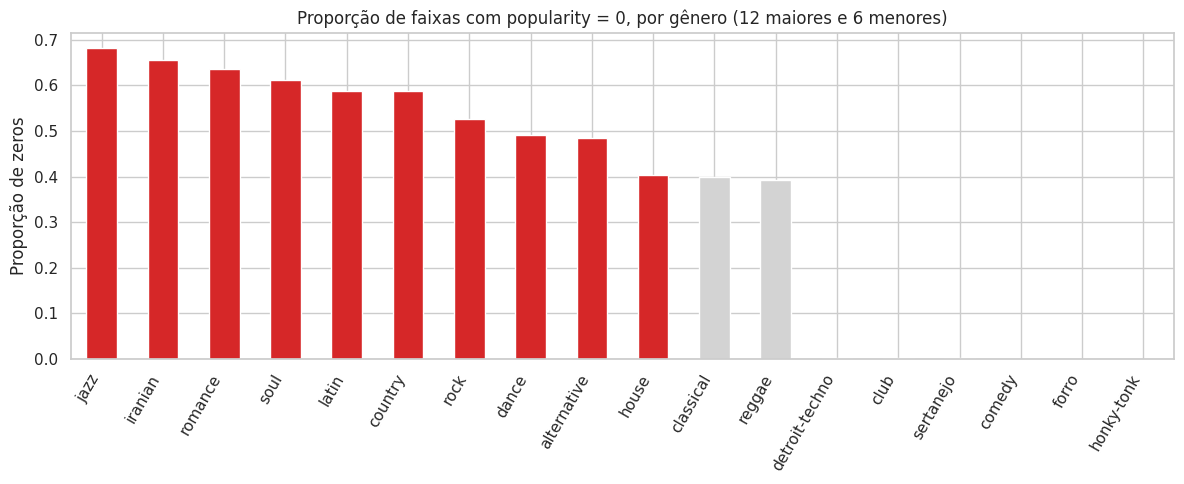

In [ ]:
zeros_por_genero = df.groupby("track_genre")["popularity"].apply(lambda s: (s == 0).mean()).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(12, 5))
top = pd.concat([zeros_por_genero.head(12), zeros_por_genero.tail(6)])
cores = [COR_ALERTA if v > 0.4 else COR_NEUTRA for v in top.values]
top.plot(kind="bar", color=cores, ax=ax)
ax.set_title("Proporção de faixas com popularity = 0, por gênero (12 maiores e 6 menores)")
ax.set_ylabel("Proporção de zeros")
ax.set_xlabel("")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

**Discussão — o achado mais importante desta EDA.**

Os zeros não estão espalhados: eles se concentram em gêneros inteiros. Em `jazz`, `iranian`, `romance`, `soul`, `latin` e `country`, **mais de 58% das faixas têm popularidade zero**; em `comedy`, `forro` e `honky-tonk`, praticamente **nenhuma**. Não existe explicação musical para isso — é implausível que 68% do jazz do catálogo tenha zero audiência enquanto 100% do forró tem alguma.

A explicação plausível é de coleta: a API deixou de retornar o campo de popularidade em determinadas requisições (um lote, uma janela de tempo, um limite de taxa atingido), e o valor default zero foi gravado no lugar. Ou seja, **são dados ausentes disfarçados**, e o mecanismo é **MAR condicional ao gênero** (a probabilidade de faltar depende de uma variável observada — o gênero — e não do valor de popularidade em si).

**Consequência prática:** qualquer ranking de popularidade por gênero feito sem tratar esses zeros vai dizer que jazz e country são impopulares, quando na verdade o que aconteceu é que os dados deles não foram coletados. Vamos lidar com isso na Seção 4.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar nada), calculamos as estatísticas descritivas. Este retrato "antes" é o que vai orientar as decisões de tratamento.

In [ ]:
VARS_QUANT = ["popularity", "duration_ms", "danceability", "energy", "loudness",
              "speechiness", "acousticness", "instrumentalness", "liveness", "valence", "tempo"]
VARS_QUALI = ["explicit", "key", "mode", "time_signature"]

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
popularity,33.24,35.00,22.31,0.00,100.00,0.05,-0.93
duration_ms,228029.15,212906.00,107297.71,0.00,5237295.00,11.20,354.95
danceability,0.57,0.58,0.17,0.00,0.98,-0.40,-0.18
energy,0.64,0.68,0.25,0.00,1.00,-0.60,-0.53
loudness,-8.26,-7.00,5.03,-49.53,4.53,-2.01,5.90
speechiness,0.08,0.05,0.11,0.00,0.96,4.65,28.82
acousticness,0.31,0.17,0.33,0.00,1.00,0.73,-0.95
instrumentalness,0.16,0.00,0.31,0.00,1.00,1.73,1.27
liveness,0.21,0.13,0.19,0.00,1.00,2.11,4.38
valence,0.47,0.46,0.26,0.00,1.00,0.12,-1.03


**Discussão:** três perfis distintos aparecem na tabela.

- **Assimetria extrema:** `duration_ms` (skew 11,2 / curtose 355) e `speechiness` (skew 4,7 / curtose 28,8). No caso da duração, isso é esperado: o dataset inclui DJ sets e mixes contínuos de mais de uma hora convivendo com faixas de 3 minutos. Não é erro, é uma cauda longa real.
- **Assimetria moderada, e explicável pela natureza da variável:** `instrumentalness` (1,7) e `liveness` (2,1). São features em que a maioria das faixas fica colada no zero — quase toda música tem vocal, quase nenhuma é gravada ao vivo — então a distribuição é naturalmente concentrada com uma cauda.
- **Quase simétricas:** `popularity` (0,05), `valence` (0,12), `tempo` (0,23), `danceability` (-0,40). Aqui as curtoses **negativas** (-0,93 para popularity, -1,03 para valence) são interessantes: indicam distribuições mais "achatadas" que a normal, sem pico central pronunciado.

`loudness` merece nota à parte: skew -2,0 com mínimo de -49,5 dB. A escala é logarítmica e limitada superiormente (não dá para passar de 0 dB sem clipar), então a cauda só pode crescer para a esquerda — a assimetria negativa é uma consequência da escala, não um defeito do dado.

### Distribuições das variáveis quantitativas

**Escolha da visualização.** Antes de decidir tratamento, precisamos ver a *forma* de cada uma das 11 variáveis quantitativas — assimetria, multimodalidade, acúmulos em valores específicos. **Histograma** é a escolha padrão aqui porque preserva a contagem bruta: um pico isolado em um único valor aparece como barra destacada, o que é exatamente o que precisamos detectar. Um boxplot mostraria os quartis mas esconderia esse acúmulo, e um gráfico de densidade o suavizaria.

Sobrepomos a curva KDE apenas como apoio visual à leitura da forma geral. Usamos uma **grade 3x4** em vez de 11 gráficos separados porque o objetivo é varredura comparativa — bater o olho e identificar quais variáveis fogem do padrão —, e painéis pequenos lado a lado servem melhor a isso que gráficos grandes em sequência.

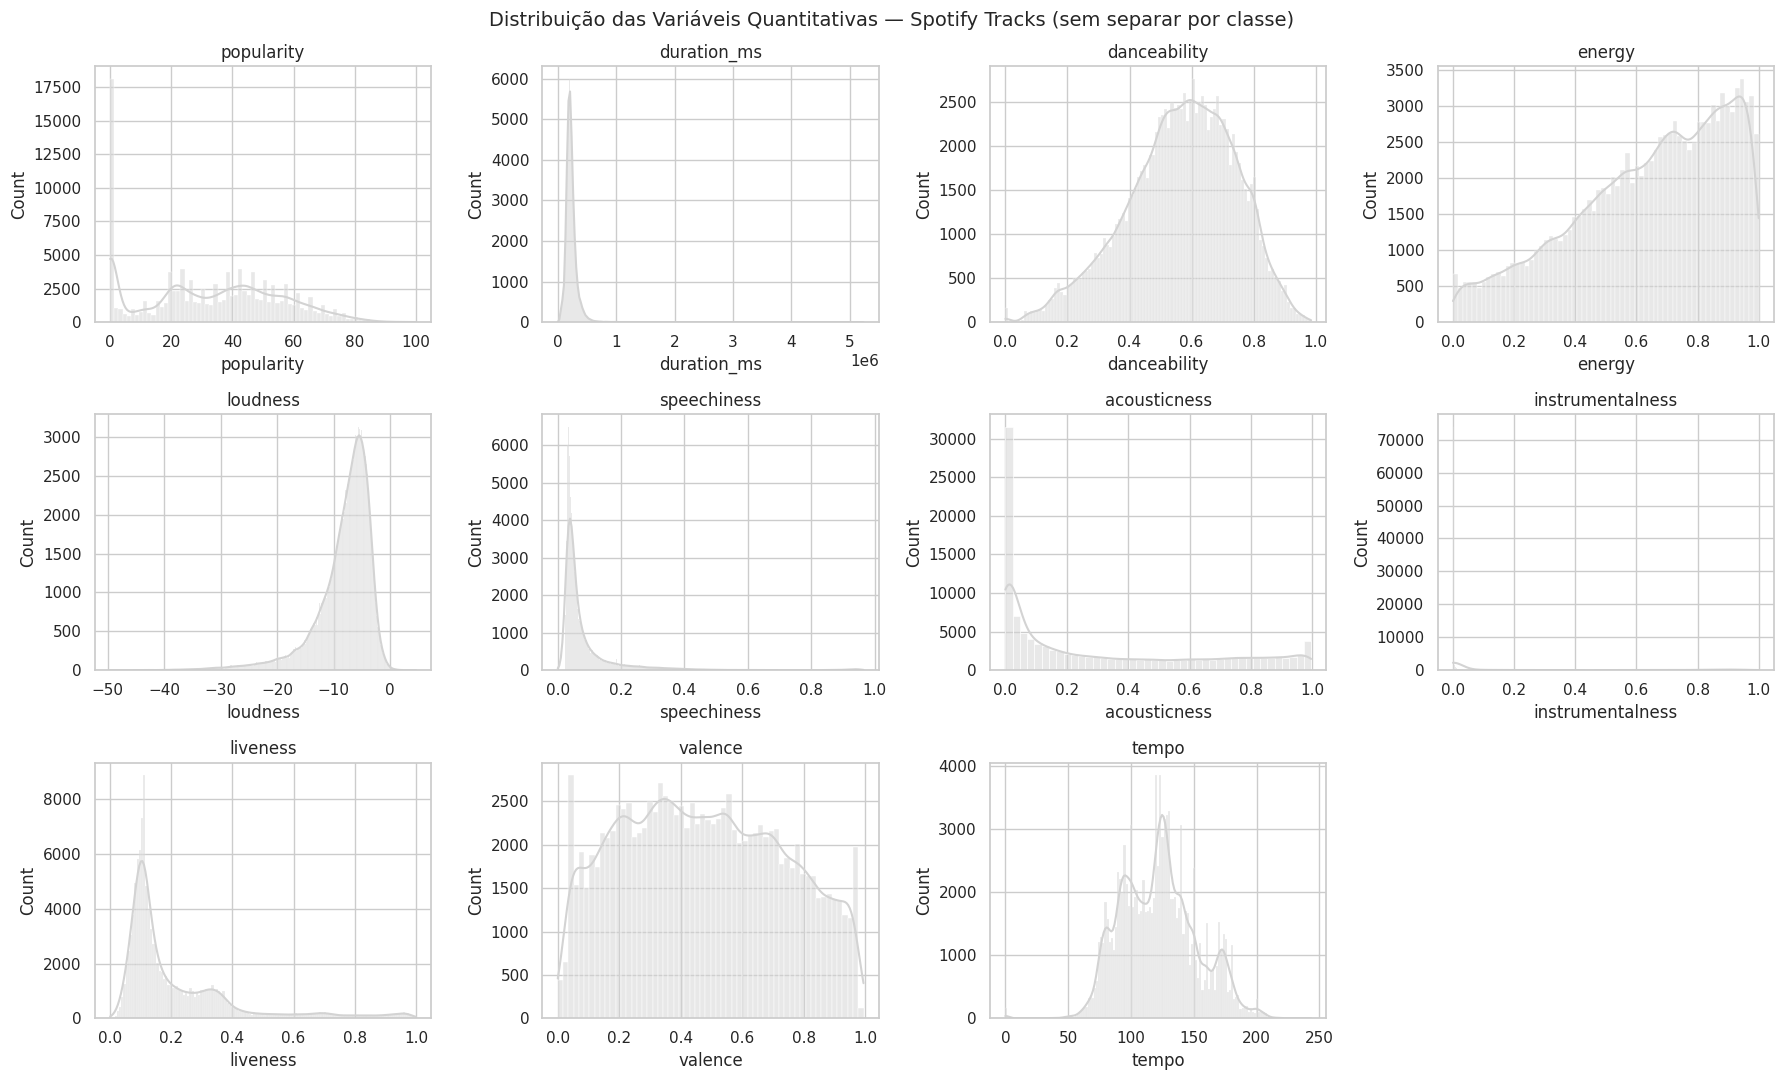

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas — Spotify Tracks (sem separar por classe)", fontsize=14)
plt.tight_layout()
plt.show()

**Discussão:** o histograma de `popularity` mostra de forma gritante o que a Seção 2 já tinha sugerido — uma barra isolada e altíssima em zero, destacada do corpo da distribuição, que por sua vez é razoavelmente bem comportada entre 10 e 80. Distribuições reais raramente têm um pico isolado exatamente no valor default de um campo; esse formato é a assinatura visual de valor faltante codificado como zero.

`instrumentalness` mostra um padrão parecido mas de origem diferente: 38.630 faixas com valor exatamente 0.000. Aqui o zero é legítimo — significa "não detectamos trecho instrumental", que é o caso da maioria das músicas com vocal.

### Comparando as classes: Popular x Nicho

**Escolha da visualização.** A pergunta muda: não é mais a forma de cada variável, e sim se essa forma **difere** entre faixas populares e de nicho. Mantemos o histograma, mas com duas mudanças obrigatórias por causa do dataset.

Primeira: usamos **densidade em vez de contagem** (`stat="density"`). Os grupos têm tamanhos muito diferentes — 84 mil faixas em Nicho contra 29 mil em Popular —, então em contagem bruta a barra rosa seria sempre quase três vezes maior, e a diferença de tamanho de amostra seria confundida com diferença de distribuição. Segunda: **painéis separados com mesmo limite de eixo X**, em vez de curvas sobrepostas, porque com distribuições quase idênticas a sobreposição vira uma mancha única e ilegível.

Limitamos a 6 variáveis (as de maior interesse interpretativo) para manter os painéis grandes o suficiente. `popularity` fica de fora por construção: é ela que define as classes.

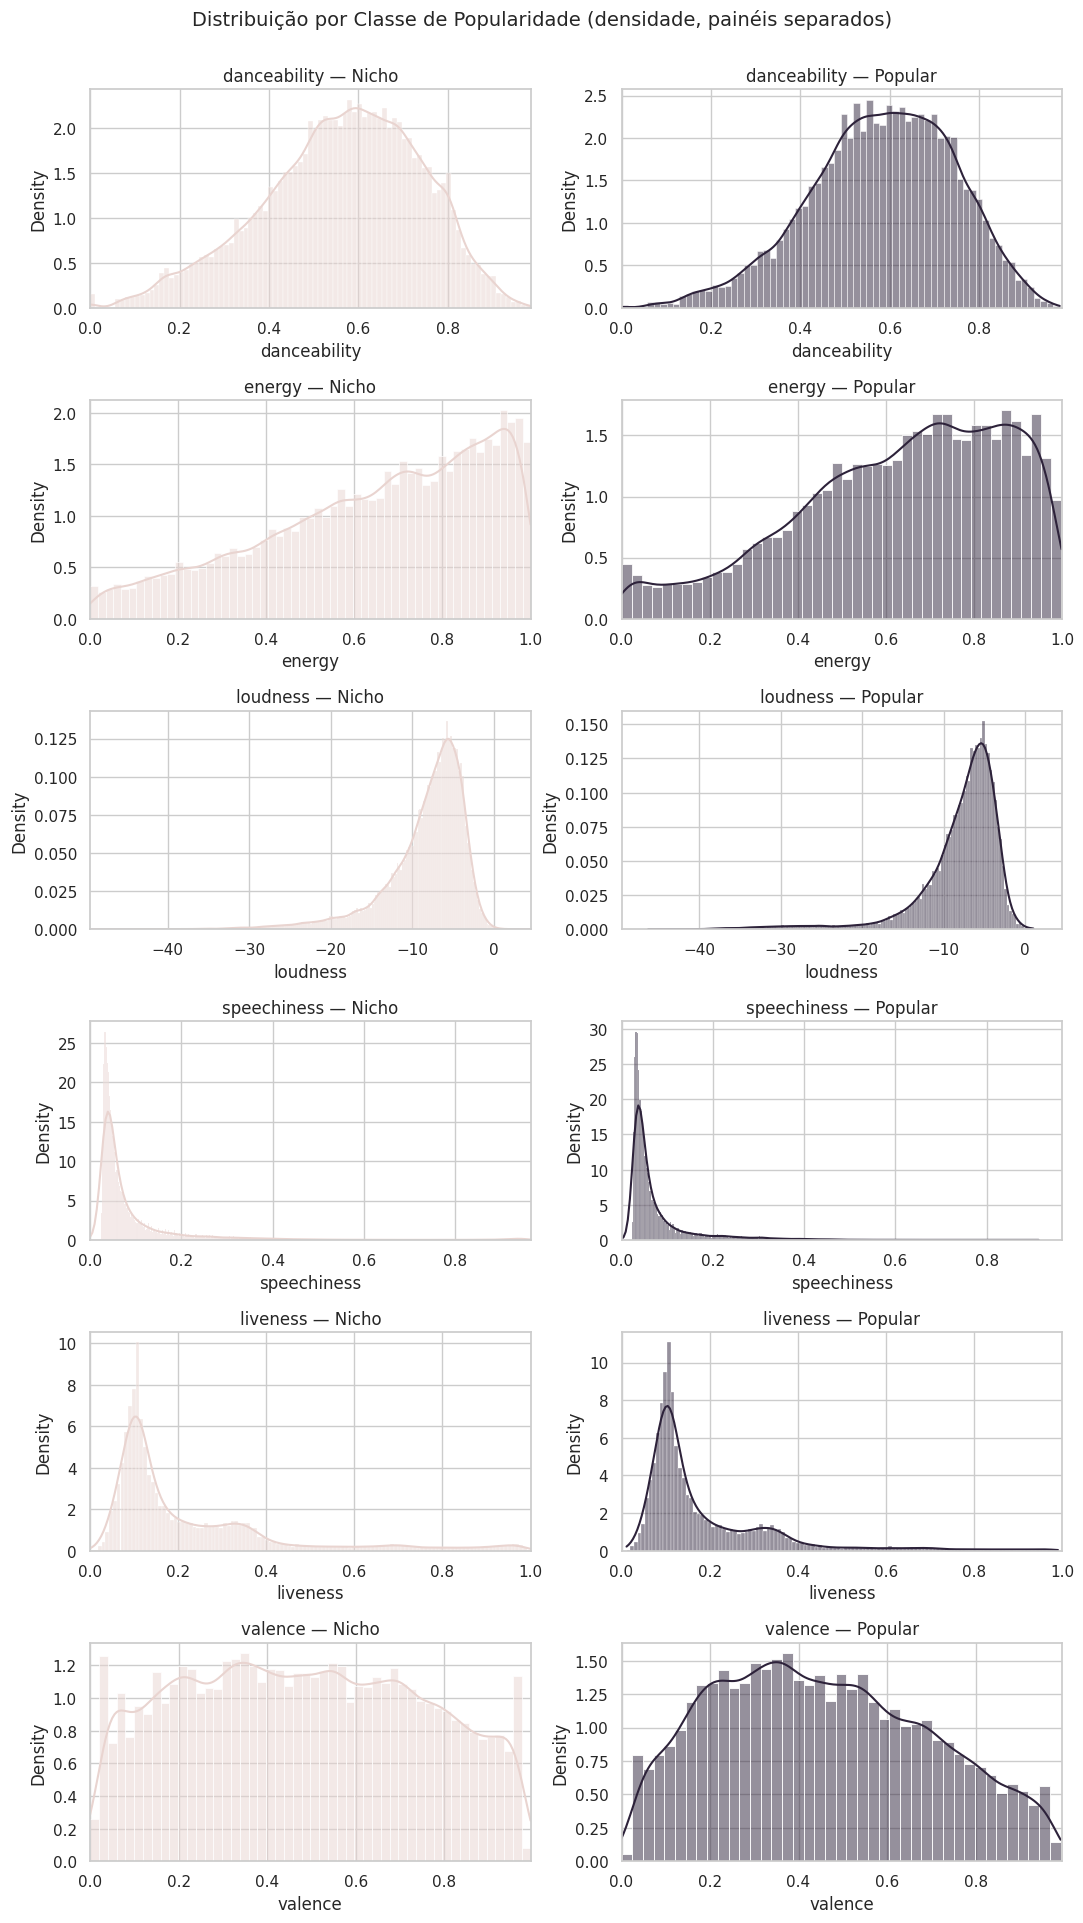

In [ ]:
VARS_FOCO = ["danceability", "energy", "loudness", "speechiness", "liveness", "valence"]

fig, axes = plt.subplots(len(VARS_FOCO), 2, figsize=(11, 3.2 * len(VARS_FOCO)))

for i, col in enumerate(VARS_FOCO):
    lim = (df[col].min(), df[col].max())
    for j, (classe, cor) in enumerate([("Nicho", COR_CONTEXTO), ("Popular", COR_DESTAQUE)]):
        subset = df[df["faixa_pop"] == classe]
        sns.histplot(data=subset, x=col, kde=True, color=cor, stat="density", ax=axes[i, j])
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}")

fig.suptitle("Distribuição por Classe de Popularidade (densidade, painéis separados)", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

**Discussão:** a resposta honesta é que **as distribuições são muito parecidas**. Usamos densidade em vez de contagem justamente para que a diferença de tamanho entre os grupos (84 mil x 29 mil) não confundisse a leitura — e mesmo assim os formatos praticamente se sobrepõem.

Isso já antecipa uma conclusão contraintuitiva: as *audio features* não separam faixas populares de faixas de nicho. Se a intuição fosse "música popular é mais dançante e mais energética", o gráfico deveria mostrar deslocamentos visíveis, e não mostra. Vamos quantificar isso na análise bivariada — inclusive porque, com 113 mil linhas, os testes estatísticos vão acusar diferença significativa de qualquer jeito, e a diferença visual (ou a falta dela) é um contraponto necessário.

**Escolha da visualização.** O Shapiro-Wilk devolve um número; o **QQ-Plot** mostra *onde* a distribuição se afasta da normal, que é a informação que o teste não dá. Escolhemos ele em vez de um histograma com curva normal sobreposta porque o QQ-Plot amplifica justamente as caudas — a região onde os desvios importam e onde um histograma mostraria apenas barras pequenas e indistinguíveis.

A leitura é direta: pontos sobre a reta vermelha indicam aderência, e o afastamento nas pontas indica cauda mais pesada ou mais leve que a normal. No nosso caso, o degrau visível na cauda inferior são as 157 faixas com `tempo = 0` — um defeito de dado que o QQ-Plot expõe graficamente e que o coeficiente de skewness (0,23, aparentemente inofensivo) escondia.

Shapiro-Wilk — tempo (amostra n=5000): estatística=0.9871, p-valor=5.44e-21
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


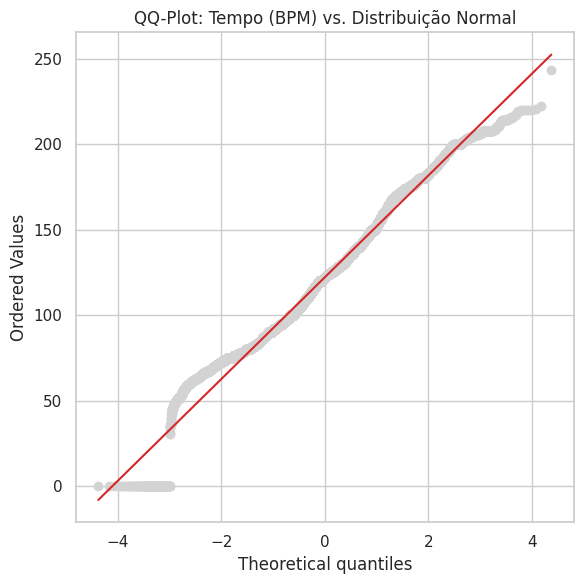

In [ ]:
amostra_tempo = df["tempo"].sample(5000, random_state=42)
stat_sw, p_valor_sw = stats.shapiro(amostra_tempo)
print(f"Shapiro-Wilk — tempo (amostra n=5000): estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["tempo"], dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: Tempo (BPM) vs. Distribuição Normal")
plt.tight_layout()
plt.show()

**Como ler:** o QQ-Plot mostra o miolo da distribuição acompanhando razoavelmente a reta, mas com desvio claro nas duas pontas — e um degrau visível na cauda inferior, que são justamente as faixas com `tempo = 0`. A combinação de Shapiro rejeitando e QQ-Plot desviando nas caudas dá uma conclusão consistente.

**Sobre como afirmar o resultado:** como o teste **rejeitou** H0, a afirmação correta é "temos evidência estatística **contra** a normalidade" — uma conclusão forte. A frase "não podemos garantir normalidade" caberia no caso oposto.

In [ ]:
resultados_shapiro = []
for col in VARS_QUANT:
    amostra = df[col].sample(5000, random_state=42)
    stat, p = stats.shapiro(amostra)
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                               "p_valor": f"{p:.3g}", "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
popularity,0.9555,1.46e-36,True
duration_ms,0.8285,1.03e-58,True
danceability,0.9875,1.21e-20,True
energy,0.9443,7.31e-40,True
loudness,0.8465,1.08e-56,True
speechiness,0.5086,8.98e-80,True
acousticness,0.8324,2.72e-58,True
instrumentalness,0.5454,4.2e-78,True
liveness,0.7356,5.59e-67,True


**Discussão:** **nenhuma** das 11 variáveis quantitativas passa no teste de normalidade, nem as que parecem simétricas. As estatísticas W deixam clara a gradação: `danceability` (0,988) e `tempo` (0,987) estão perto de uma normal; `speechiness` (0,509) e `instrumentalness` (0,545) estão muito longe.

Isso tem consequência direta na Seção 6: todos os testes paramétricos (t-test, ANOVA, correlação de Pearson) ficam tecnicamente inadequados. Vamos usar os equivalentes não-paramétricos como resultado principal.

**Escolha da visualização.** A **ECDF** resolve um problema concreto que o histograma tem neste caso: comparar duas distribuições quase idênticas. O histograma exige escolher a largura do bin, e essa escolha pode criar ou apagar diferenças pequenas — exatamente a faixa de diferença que estamos investigando aqui. A ECDF não tem esse parâmetro: para cada valor no eixo X, a curva mostra a proporção acumulada de observações menores ou iguais.

Isso torna a leitura da diferença entre grupos objetiva: onde as curvas mais se distanciam verticalmente está a região de maior discrepância, e a distância máxima entre elas é interpretável diretamente (é a estatística do teste de Kolmogorov-Smirnov). Com 113 mil observações, a curva fica praticamente contínua, sem o ruído que a ECDF costuma ter em amostras pequenas.

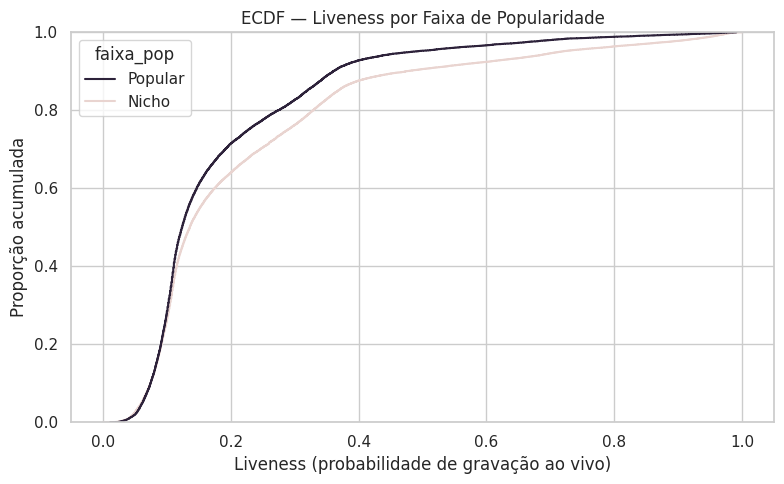

In [ ]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="liveness", hue="faixa_pop",
             palette={"Nicho": COR_CONTEXTO, "Popular": COR_DESTAQUE})
plt.title("ECDF — Liveness por Faixa de Popularidade")
plt.xlabel("Liveness (probabilidade de gravação ao vivo)")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva diz que fração das faixas daquele grupo tem liveness até ali. As duas curvas se distanciam de leve na faixa de 0,1 a 0,3 — as faixas populares acumulam um pouco mais rápido, ou seja, tendem a ter menos "cara de ao vivo". Mas o afastamento máximo entre as curvas é pequeno: a diferença existe e é consistente, só não é grande.

### Métricas de Tendência Central

**Escolha da visualização.** Média e mediana são dois números — não precisariam de gráfico. O que justifica a visualização aqui é a pergunta seguinte: *por que* elas divergem (ou não) em uma variável com skewness 11,2. Isso só se responde vendo a distribuição com as duas marcadas em cima dela, o que um par de números isolados não permite.

Usamos **linhas verticais sobre o histograma**, com estilos diferentes (tracejada vermelha para a média, sólida preta para a mediana) para que sejam distinguíveis sem depender de cor. Convertemos o eixo para **minutos** em vez de milissegundos, porque a unidade original não tem leitura intuitiva. E **cortamos o eixo em 15 minutos**: sem o corte, a cauda de até 87 minutos comprime 99% dos dados no canto esquerdo e o gráfico não mostra nada. O corte está declarado no título, já que omitir parte do domínio sem avisar seria enganoso.

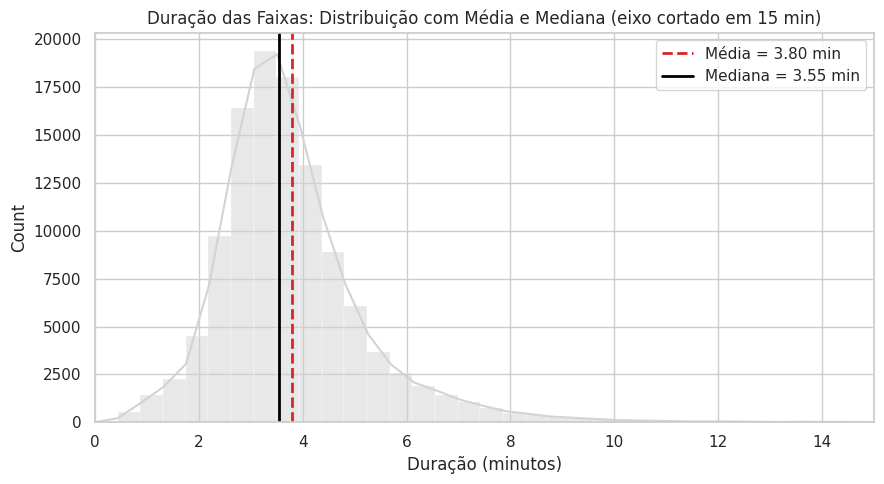

In [ ]:
media_dur = df["duration_ms"].mean() / 60000
mediana_dur = df["duration_ms"].median() / 60000

plt.figure(figsize=(9, 5))
sns.histplot(x=df["duration_ms"] / 60000, kde=True, color=COR_NEUTRA, bins=200)
plt.axvline(media_dur, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_dur:.2f} min")
plt.axvline(mediana_dur, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_dur:.2f} min")
plt.xlim(0, 15)
plt.xlabel("Duração (minutos)")
plt.title("Duração das Faixas: Distribuição com Média e Mediana (eixo cortado em 15 min)")
plt.legend()
plt.tight_layout()
plt.show()

**Discussão:** média e mediana quase coincidem no gráfico, o que à primeira vista sugere simetria — mas a skewness de 11,2 diz o contrário. A explicação é que a cauda, embora chegue a **87 minutos**, tem pouquíssimos casos: são raros o suficiente para mal deslocarem a média, mas suficientes para dominar o cálculo do momento de terceira ordem.

Isso é um bom lembrete de que assimetria alta não implica automaticamente grande distância entre média e mediana. Para decidir o tratamento, importa mais *o que são* esses pontos extremos do que o valor do coeficiente — e é isso que a Seção 4 investiga. Note também que precisamos cortar o eixo em 15 minutos para o gráfico ser legível: sem isso, 99% dos dados se espremem no canto esquerdo.

### Dispersão por classe

**Escolha da visualização.** A pergunta é se a dispersão das audio features difere entre Popular e Nicho. Boxplot e violin plot respondem os dois, então usar os dois seria mostrar a mesma informação em duas codificações.

**Optamos pelo violin plot**, por dois motivos. Primeiro, ele contém o boxplot: com `inner="box"`, a caixa e a mediana aparecem desenhadas dentro de cada violino, então nada se perde. Segundo, ele mostra o que o boxplot esconde — a *forma* da distribuição. Isso não é detalhe estético aqui: `speechiness` e `liveness` têm massa concentrada perto de zero com cauda fina, e é essa forma que vai explicar por que a regra do IQR falha na Seção 4. Um boxplot mostraria só uma caixa achatada, sem o porquê.

As medidas numéricas de dispersão (variância, desvio-padrão, IQR) vão em **tabela**, não em gráfico: são 11 valores por métrica, que se leem melhor lidos que vistos.

,var,std,IQR
popularity,4.975170e+02,22.305,33.000
duration_ms,1.151280e+10,107297.713,87440.000
danceability,3.000000e-02,0.174,0.239
energy,6.300000e-02,0.252,0.382
loudness,2.529400e+01,5.029,5.010
speechiness,1.100000e-02,0.106,0.049
acousticness,1.110000e-01,0.333,0.581
instrumentalness,9.600000e-02,0.310,0.049
liveness,3.600000e-02,0.190,0.175
valence,6.700000e-02,0.259,0.423


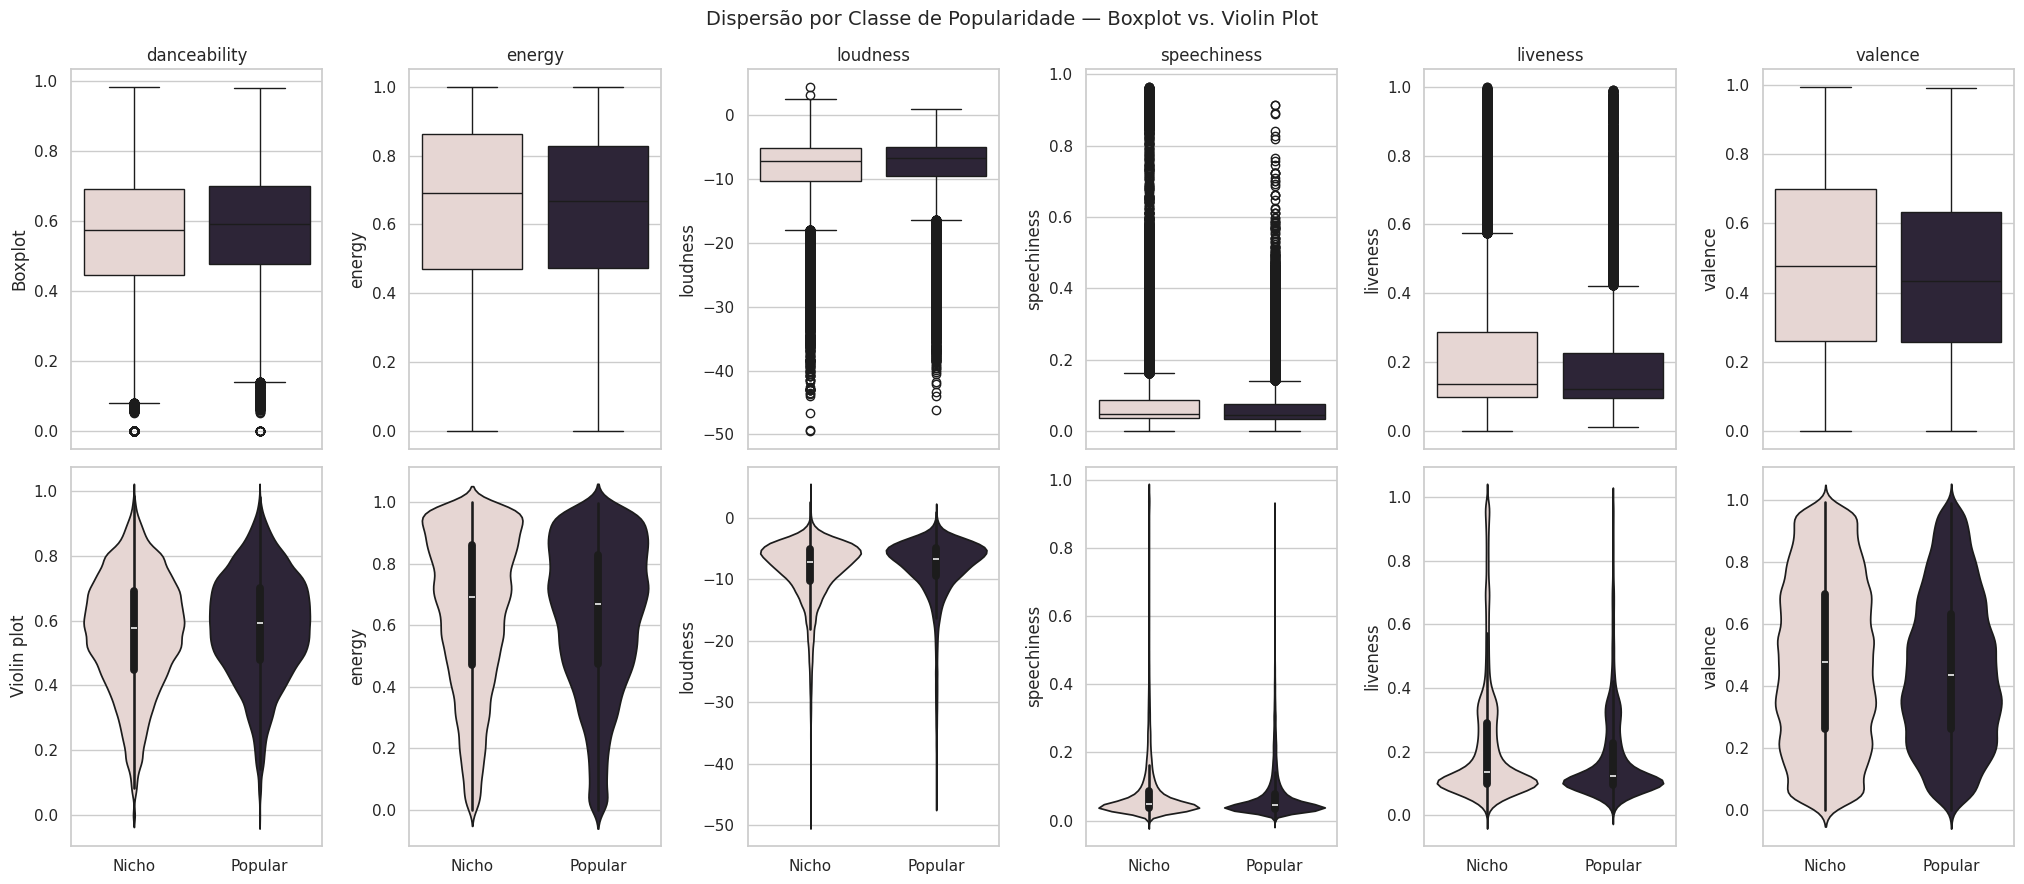

In [ ]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
display(dispersao.round(3))

palette_classe = {"Nicho": COR_CONTEXTO, "Popular": COR_DESTAQUE}

fig, axes = plt.subplots(2, len(VARS_FOCO), figsize=(3.4 * len(VARS_FOCO), 9), sharex="col")

for i, col in enumerate(VARS_FOCO):
    sns.boxplot(data=df, x="faixa_pop", y=col, hue="faixa_pop", order=["Nicho", "Popular"],
                palette=palette_classe, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, x="faixa_pop", y=col, hue="faixa_pop", order=["Nicho", "Popular"],
                   palette=palette_classe, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Classe de Popularidade — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

**Discussão:** nenhuma caixa está nitidamente deslocada entre Nicho e Popular. As medianas se movem em uma casa decimal e as caixas (IQR) praticamente se sobrepõem em todas as seis variáveis. Comparando com o caso do Heart Disease visto em aula — onde `thalach` e `oldpeak` mostravam caixas claramente separadas entre as classes — a diferença de comportamento é gritante.

O violin plot acrescenta uma informação que o boxplot esconde: `speechiness` e `liveness` são fortemente concentradas perto de zero em **ambos** os grupos, com uma cauda fina. É essa concentração que vai fazer a regra do IQR se comportar mal na próxima seção.

## 4. Tratamento de Dados Ausentes e Outliers

Com o retrato "antes" na mão, temos a informação que faltava para decidir o tratamento. A regra que vamos seguir é a da aula: classificar cada outlier antes de decidir o que fazer com ele.

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

### Detecção de Outliers por IQR

In [ ]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = int(((df[col] < lim_inf) | (df[col] > lim_sup)).sum())
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
        "pct": round(100 * n_outliers / len(df), 2),
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers,pct
popularity,-32.50,99.50,2.0,0.00
duration_ms,42906.00,392666.00,5617.0,4.93
danceability,0.10,1.05,620.0,0.54
energy,-0.10,1.43,0.0,0.00
loudness,-17.53,2.51,6173.0,5.41
speechiness,-0.04,0.16,13211.0,11.59
acousticness,-0.85,1.47,0.0,0.00
instrumentalness,-0.07,0.12,25246.0,22.15
liveness,-0.16,0.54,8642.0,7.58
valence,-0.37,1.32,0.0,0.00


### Visualizando os outliers

**Escolha da visualização.** A Seção 3 já mostrou a distribuição destas mesmas variáveis, então cabe justificar por que há outro gráfico aqui: **a pergunta é diferente**. Lá, era qual a forma da distribuição; aqui é *quais pontos específicos a regra do IQR classifica como outlier* — e nenhum gráfico anterior marca isso.

**Optamos pelo boxplot**, e não por um histograma com linhas de corte, porque o boxplot é a representação gráfica direta da própria regra: a caixa é o IQR, as hastes são os limites de 1,5 x IQR, e os pontos além delas são exatamente o que a regra marca. Gráfico e critério são a mesma construção, o que torna o diagnóstico da discussão abaixo visualmente óbvio em vez de dedutivo. Os pontos marcados vão em **vermelho**, seguindo a convenção de cor de atenção da aula.

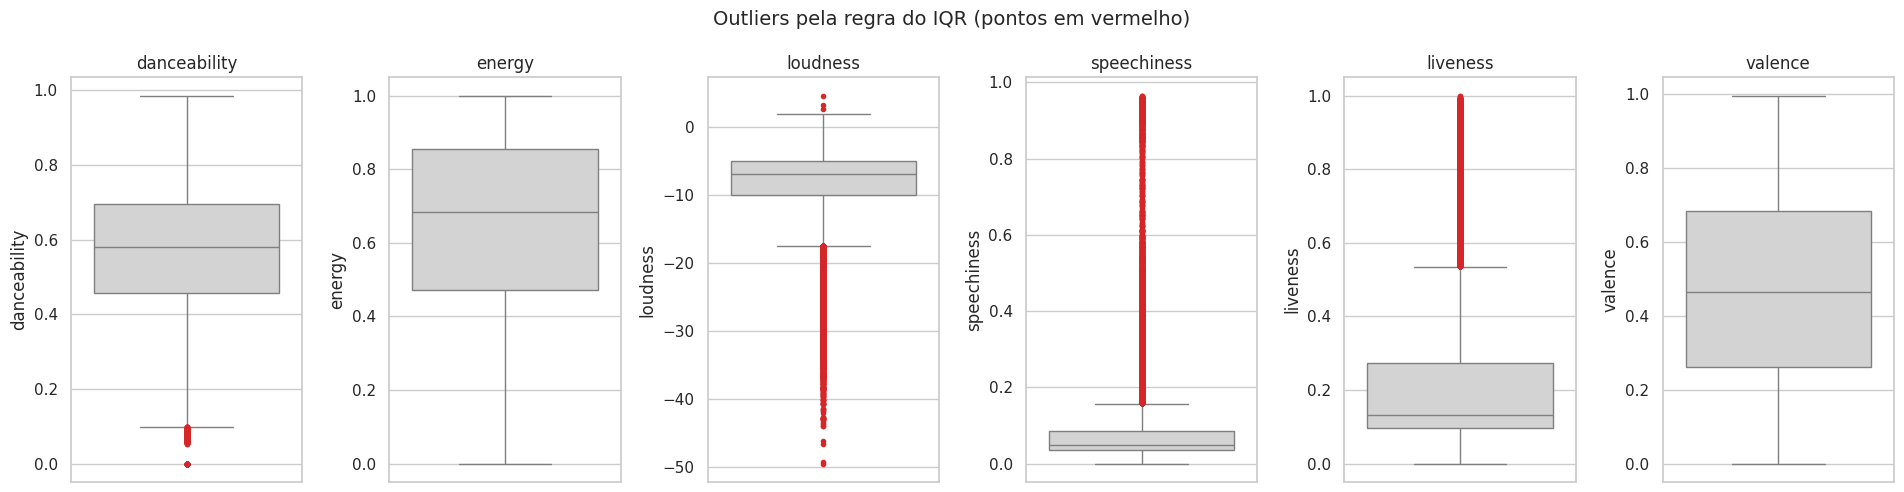

In [ ]:
fig, axes = plt.subplots(1, len(VARS_FOCO), figsize=(3.2 * len(VARS_FOCO), 5))

for i, col in enumerate(VARS_FOCO):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o", markersize=3),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

**Discussão — quando a própria regra do IQR é o problema.**

A tabela acusa **22,2% de outliers em `instrumentalness`** e **11,6% em `speechiness`**. Um quinto da base não pode ser "raro" — isso é uma contradição em termos, e o sinal de que a ferramenta está sendo mal aplicada.

O que acontece é o seguinte: `instrumentalness` tem mediana exatamente 0,000 e Q3 = 0,049, porque a maioria esmagadora das faixas tem vocal. O IQR resultante é minúsculo (0,049), então o limite superior cai em 0,12 — e **toda faixa genuinamente instrumental** (um estudo de piano, uma trilha ambiente) é marcada como outlier. O mesmo vale para `speechiness`: podcasts, faixas de comédia e spoken word são conteúdo legítimo do catálogo, e a regra os expulsa em bloco.

**Conclusão de método:** a regra do IQR pressupõe uma distribuição unimodal e razoavelmente simétrica. Para variáveis limitadas em [0,1] com massa concentrada em uma extremidade, ela não detecta anomalia — ela detecta a própria assimetria. Aqui esses casos se classificam como **outliers estatísticos legítimos**, e a decisão é **manter**.

Também vale notar o inverso: `energy`, `acousticness` e `valence` registram **zero outliers**. Não porque sejam bem comportadas, mas porque são limitadas em [0,1] e bem espalhadas — os limites do IQR caem fora do domínio possível da variável. Uma variável com zero outliers pelo IQR não é necessariamente uma variável limpa.

### Outliers de domínio: valores fisicamente impossíveis

O IQR não pegou os casos realmente problemáticos, porque eles não estão nas caudas — estão exatamente no zero, dentro dos limites. É aqui que o conhecimento de domínio faz o trabalho que a estatística sozinha não faz.

In [ ]:
print("duration_ms == 0 :", int((df["duration_ms"] == 0).sum()), "-> faixa de duração zero não existe")
print("tempo == 0       :", int((df["tempo"] == 0).sum()), "-> não existe música a 0 BPM")
print("time_signature 0 :", int((df["time_signature"] == 0).sum()), "-> não existe compasso com 0 tempos")

print("\nAs cinco faixas mais longas da base:")
display(df.nlargest(5, "duration_ms")[["track_name", "artists", "track_genre", "duration_ms"]]
          .assign(minutos=lambda d: (d["duration_ms"] / 60000).round(1)))

duration_ms == 0 : 1 -> faixa de duração zero não existe
tempo == 0       : 157 -> não existe música a 0 BPM
time_signature 0 : 163 -> não existe compasso com 0 tempos

As cinco faixas mais longas da base:


,track_name,artists,track_genre,duration_ms,minutos
73617,Unity (Voyage Mix) Pt. 1,Tale Of Us,minimal-techno,5237295,87.3
10935,Crossing Wires 002 - Continuous DJ Mix,Timo Maas,breakbeat,4789026,79.8
10984,Crossing Wires 002 - Continuous DJ Mix,Timo Maas,breakbeat,4789026,79.8
24348,The Lab 03 - Continuous DJ Mix Part 1,Seth Troxler,detroit-techno,4730302,78.8
73840,Amnesia Ibiza Underground 10 DJ Mix,Loco Dice,minimal-techno,4563897,76.1


**Classificação dos três casos:**

- `duration_ms = 0` (1 faixa), `tempo = 0` (157 faixas) e `time_signature = 0` (163 faixas) violam condições físicas. São **erros de dados** — o valor não pôde ser estimado pelo algoritmo de análise de áudio do Spotify e foi gravado como zero. Não há como corrigir (não temos o áudio), então a remoção se justifica: são 321 linhas em 114 mil, **menos de 0,3% da base**.
- As faixas de 60 a 87 minutos **não** são erro. São DJ sets e mixes contínuos ("Continuous DJ Mix", "House of Om"), concentrados justamente nos gêneros de eletrônica. São **outliers estatísticos legítimos** e removê-los apagaria uma característica real do catálogo. Decisão: **manter**.

### Aplicando o tratamento

In [ ]:
df_antes = df.copy()
linhas_antes = len(df)

df = df.dropna(subset=["track_name"])
n_dup = int(df.duplicated().sum())
df = df.drop_duplicates()

df.loc[df["duration_ms"] == 0, "duration_ms"] = np.nan
df.loc[df["tempo"] == 0, "tempo"] = np.nan
df.loc[df["time_signature"] == 0, "time_signature"] = np.nan
df = df.dropna(subset=["duration_ms", "tempo", "time_signature"]).reset_index(drop=True)
df["time_signature"] = df["time_signature"].astype(int)

print(f"Linhas antes: {linhas_antes} | depois: {len(df)} | removidas: {linhas_antes - len(df)} "
      f"({100 * (linhas_antes - len(df)) / linhas_antes:.2f}%)")
print(f"  - 1 linha com metadados ausentes (MCAR)")
print(f"  - {n_dup} linhas duplicadas exatas")
print(f"  - restante: valores fisicamente impossíveis em duration_ms / tempo / time_signature")

Linhas antes: 114000 | depois: 113386 | removidas: 614 (0.54%)
  - 1 linha com metadados ausentes (MCAR)
  - 450 linhas duplicadas exatas
  - restante: valores fisicamente impossíveis em duration_ms / tempo / time_signature


**Sobre as 450 duplicadas exatas:** são diferentes das repetições multi-gênero que vimos na Seção 1. Aqui a linha inteira se repete, **inclusive o gênero** — não há informação nova, é redundância de coleta pura. Remover é seguro.

### E as repetições multi-gênero? A decisão de grão

Restam cerca de 24 mil linhas em que a mesma faixa aparece sob gêneros diferentes. Antes de decidir, vale medir o impacto de desduplicar.

In [ ]:
unicas = df.drop_duplicates(subset="track_id")

comparacao_grao = pd.DataFrame({
    "grão faixa x gênero": [len(df), round(df["popularity"].mean(), 2), round((df["popularity"] >= 50).mean(), 4)],
    "grão faixa única":    [len(unicas), round(unicas["popularity"].mean(), 2), round((unicas["popularity"] >= 50).mean(), 4)],
}, index=["n linhas", "popularidade média", "proporção Popular"])
comparacao_grao

,grão faixa x gênero,grão faixa única
n linhas,113386.0000,89578.0000
popularidade média,33.3200,33.1900
proporção Popular,0.2587,0.2366


**Discussão:** desduplicar reduz a base em 21% mas muda a popularidade média em apenas 0,13 ponto (33,32 -> 33,19) e a proporção de faixas populares em 2,2 pontos (25,9% -> 23,7%). O efeito existe e está na direção esperada — faixas que aparecem em muitos gêneros tendem a ser mais populares, então mantê-las repetidas infla levemente a popularidade média —, mas é pequeno.

**Decisão: manter o grão faixa x gênero.** O motivo é que as perguntas que guiam esta EDA envolvem gênero, e desduplicar exigiria escolher arbitrariamente um gênero para cada faixa multi-gênero (qual seria o gênero "verdadeiro" de Badfinger — blues, folk ou power-pop?). Registramos a distorção e a consideramos na interpretação, em vez de resolvê-la com uma escolha arbitrária.

### E os zeros de `popularity`?

Este é o caso mais delicado, e merece uma decisão explícita em vez de automática. As três opções:

1. **Remover as ~16 mil linhas com popularidade zero.** Descarta 14% da base e, pior, remove de forma *enviesada* — jazz perderia 68% das faixas, forró nenhuma. A base ficaria ainda menos representativa.
2. **Imputar.** Imputar pela mediana do gênero é circular quando a pergunta é justamente comparar popularidade entre gêneros: estaríamos inventando o resultado a partir de uma mediana calculada sobre os poucos casos sobreviventes.
3. **Manter, marcar e segmentar a análise.**

**Decisão: opção 3.** Criamos um indicador `pop_suspeita` e, sempre que a análise envolver popularidade entre gêneros, rodamos nos dois recortes — com e sem os zeros — comparando os resultados. Tratar dado ausente não significa necessariamente apagá-lo ou preenchê-lo; às vezes a decisão mais honesta é torná-lo visível e carregá-lo explicitamente pela análise.

In [ ]:
df["pop_suspeita"] = df["popularity"] == 0
print("Faixas marcadas como popularidade suspeita:", int(df["pop_suspeita"].sum()))
df_pop_valida = df[~df["pop_suspeita"]].copy()
print("Base para análises de popularidade entre gêneros:", len(df_pop_valida), "linhas")

Faixas marcadas como popularidade suspeita: 15839
Base para análises de popularidade entre gêneros: 97547 linhas


**Escolha da visualização.** A pergunta é se a transformação logarítmica resolve a assimetria. Poderíamos responder só com o número (skewness antes e depois), mas o número não diz *o que aconteceu com a forma* — e é isso que decide se a transformação é aceitável ou se distorceu o dado.

Usamos **dois histogramas lado a lado, com a skewness no título de cada um**, combinando a evidência visual e a numérica no mesmo gráfico. Painéis separados em vez de sobreposição porque as escalas do eixo X são incomparáveis depois do log — sobrepor exigiria um eixo comum que não existe. Aumentamos para 100 bins porque, com 113 mil observações, a resolução padrão do seaborn achataria a estrutura da cauda, que é justamente o que a transformação altera.

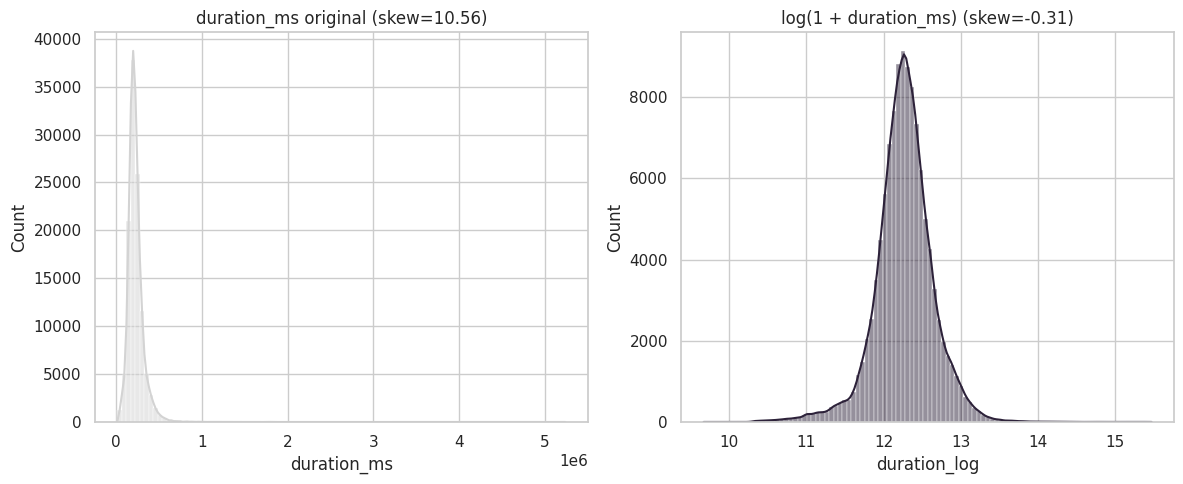

In [ ]:
df["duration_log"] = np.log1p(df["duration_ms"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="duration_ms", kde=True, color=COR_NEUTRA, bins=100, ax=axes[0])
axes[0].set_title(f"duration_ms original (skew={df['duration_ms'].skew():.2f})")

sns.histplot(data=df, x="duration_log", kde=True, color=COR_DESTAQUE, bins=100, ax=axes[1])
axes[1].set_title(f"log(1 + duration_ms) (skew={df['duration_log'].skew():.2f})")

plt.tight_layout()
plt.show()

**Discussão:** a transformação levou a skewness de **+10,6 para -0,31** — de uma das distribuições mais assimétricas da base para praticamente simétrica, sem descartar uma linha sequer. Vale registrar que ela passou do lado positivo para o negativo: o log "puxou demais", o que é comum quando a cauda é muito longa. Mantemos `duration_log` disponível, mas as seções seguintes usam a variável original, já que os testes que vamos usar são não-paramétricos e não exigem normalidade.

## 5. Estatística Descritiva pt. 2

Fechando o ciclo iterativo: rodamos a mesma bateria da Seção 3 para comparar diretamente com o "antes".

In [ ]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
popularity,33.32,35.00,22.30,0.00,100.00,0.04,-0.93
duration_ms,228160.21,213066.00,105411.84,15800.00,5237295.00,10.56,333.74
danceability,0.57,0.58,0.17,0.05,0.98,-0.37,-0.26
energy,0.64,0.69,0.25,0.00,1.00,-0.60,-0.53
loudness,-8.22,-6.99,4.97,-46.59,4.53,-1.99,5.81
speechiness,0.08,0.05,0.11,0.02,0.96,4.64,28.78
acousticness,0.31,0.17,0.33,0.00,1.00,0.73,-0.94
instrumentalness,0.16,0.00,0.31,0.00,1.00,1.74,1.30
liveness,0.21,0.13,0.19,0.01,1.00,2.11,4.40
valence,0.47,0.46,0.26,0.00,1.00,0.12,-1.03


### Comparando "antes" x "depois"

In [ ]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
popularity,0.046,0.043,-0.928,-0.926,-0.004,0.002
duration_ms,11.195,10.563,354.952,333.742,-0.632,-21.210
danceability,-0.399,-0.374,-0.185,-0.255,0.026,-0.071
energy,-0.597,-0.596,-0.526,-0.525,0.001,0.001
loudness,-2.007,-1.992,5.896,5.811,0.015,-0.086
speechiness,4.648,4.645,28.824,28.780,-0.003,-0.045
acousticness,0.727,0.731,-0.950,-0.942,0.004,0.008
instrumentalness,1.734,1.744,1.271,1.305,0.009,0.034
liveness,2.106,2.109,4.378,4.402,0.003,0.024
valence,0.115,0.116,-1.027,-1.028,0.001,-0.001


**Discussão:** as mudanças são pequenas na maioria das variáveis, o que é esperado — removemos 0,54% das linhas e decidimos não mexer em nenhum outlier estatístico. O tratamento foi conservador de propósito.

As exceções são justamente as variáveis que tinham valores impossíveis:

- **`duration_ms`**: skewness cai de 11,20 para 10,56 e curtose de 355 para 334. A única faixa de duração zero puxava a distribuição sozinha.
- **`tempo`**: skewness sobe de 0,23 para 0,32 e a curtose muda de -0,11 para -0,38 — o mínimo sai de 0 para 30,2 BPM. Note que a skewness **piorou** em valor absoluto. Isso é correto: os 157 zeros formavam uma cauda esquerda artificial que compensava a assimetria à direita. Remover erro nem sempre "melhora" os indicadores, e um coeficiente que piora depois de uma limpeza justificada não é motivo para desfazer a limpeza.

Esse último ponto é o valor da comparação antes/depois: ela mostra o efeito real das decisões em vez de assumi-lo.

**O tempo ainda rejeita normalidade depois da limpeza?**

In [ ]:
amostra_depois = df["tempo"].sample(5000, random_state=42)
stat_depois, p_depois = stats.shapiro(amostra_depois)
print(f"Shapiro-Wilk (antes)  — tempo: W={stat_sw:.4f}, p={p_valor_sw:.4g}")
print(f"Shapiro-Wilk (depois) — tempo: W={stat_depois:.4f}, p={p_depois:.4g}")

Shapiro-Wilk (antes)  — tempo: W=0.9871, p=5.44e-21
Shapiro-Wilk (depois) — tempo: W=0.9869, p=3.682e-21


**Escolha da visualização.** A tabela acima responde *quanto* cada indicador mudou nas 11 variáveis. Ela não responde **onde na distribuição** a mudança ocorreu — e essa é a pergunta que confirma se removemos o que pretendíamos remover, em vez de ter cortado uma faixa legítima do dado.

Usamos **curvas de densidade sobrepostas** em vez de histogramas porque aqui o que interessa é a comparação de duas silhuetas, e barras sobrepostas de dois estados se oclui-riam mutuamente. Limitamos a **duas variáveis** — `tempo` e `duration_ms` — que são as únicas em que o tratamento removeu linhas; nas outras nove nada foi alterado, e sobrepor curvas idênticas seria ruído. Mantemos a convenção de cor do notebook: rosa para o estado anterior, roxo para o tratado. O eixo de `duration_ms` fica **cortado em 15 minutos** pelo mesmo motivo da Seção 3, com o corte declarado no título.

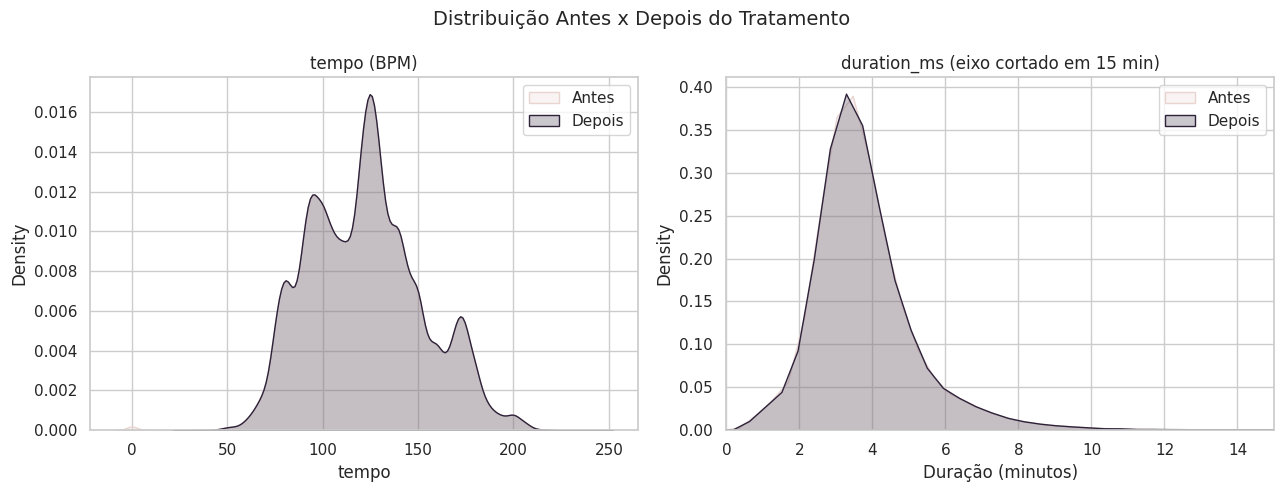

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.kdeplot(df_antes["tempo"], color=COR_CONTEXTO, fill=True, label="Antes", ax=axes[0])
sns.kdeplot(df["tempo"], color=COR_DESTAQUE, fill=True, label="Depois", ax=axes[0])
axes[0].set_title("tempo (BPM)")
axes[0].legend()

sns.kdeplot(df_antes["duration_ms"] / 60000, color=COR_CONTEXTO, fill=True, label="Antes", ax=axes[1])
sns.kdeplot(df["duration_ms"] / 60000, color=COR_DESTAQUE, fill=True, label="Depois", ax=axes[1])
axes[1].set_xlim(0, 15)
axes[1].set_xlabel("Duração (minutos)")
axes[1].set_title("duration_ms (eixo cortado em 15 min)")
axes[1].legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=14)
plt.tight_layout()
plt.show()

**Discussão:** em `tempo`, a diferença é localizada e visível — a pequena elevação em zero na curva "antes" desaparece na curva "depois". Em `duration_ms`, as curvas se sobrepõem quase perfeitamente, como esperado para a remoção de uma única linha. Os dois padrões juntos confirmam que o tratamento fez exatamente o que deveria: corrigiu onde havia erro e deixou o resto intacto.

## 6. Princípio Relacional

### Análise das variáveis qualitativas

**Escolha da visualização.** Para variáveis nominais e ordinais de poucas categorias (`explicit`, `key`, `mode`, `time_signature`), a pergunta é a frequência de cada categoria. **Barras verticais** são a codificação adequada: comparação por comprimento, sem sugerir continuidade entre categorias — o que um gráfico de linha faria erroneamente com `key`, por exemplo, já que a distância entre tonalidades não é numérica.

Descartamos gráfico de pizza deliberadamente: com `time_signature` em 90% numa categoria e o restante dividido em três fatias minúsculas, ângulos seriam impossíveis de comparar. Ordenamos por **índice da categoria** e não por frequência, porque `key` e `time_signature` têm ordem natural que a leitura deve preservar. `track_genre` fica fora deste gráfico — 114 barras seriam ilegíveis, e ele recebe tratamento próprio abaixo.

In [ ]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))


--- explicit ---
          absoluta  relativa
explicit                    
False       103668     0.914
True          9718     0.086

--- key ---
     absoluta  relativa
key                    
7       13191     0.116
0       12989     0.115
2       11574     0.102
9       11253     0.099
1       10711     0.094
5        9319     0.082
11       9242     0.082
4        8967     0.079
6        7883     0.070
10       7392     0.065
8        7323     0.065
3        3542     0.031

--- mode ---
      absoluta  relativa
mode                    
1        72318     0.638
0        41068     0.362

--- time_signature ---
                absoluta  relativa
time_signature                    
4                 101486     0.895
3                   9128     0.081
5                   1805     0.016
1                    967     0.009


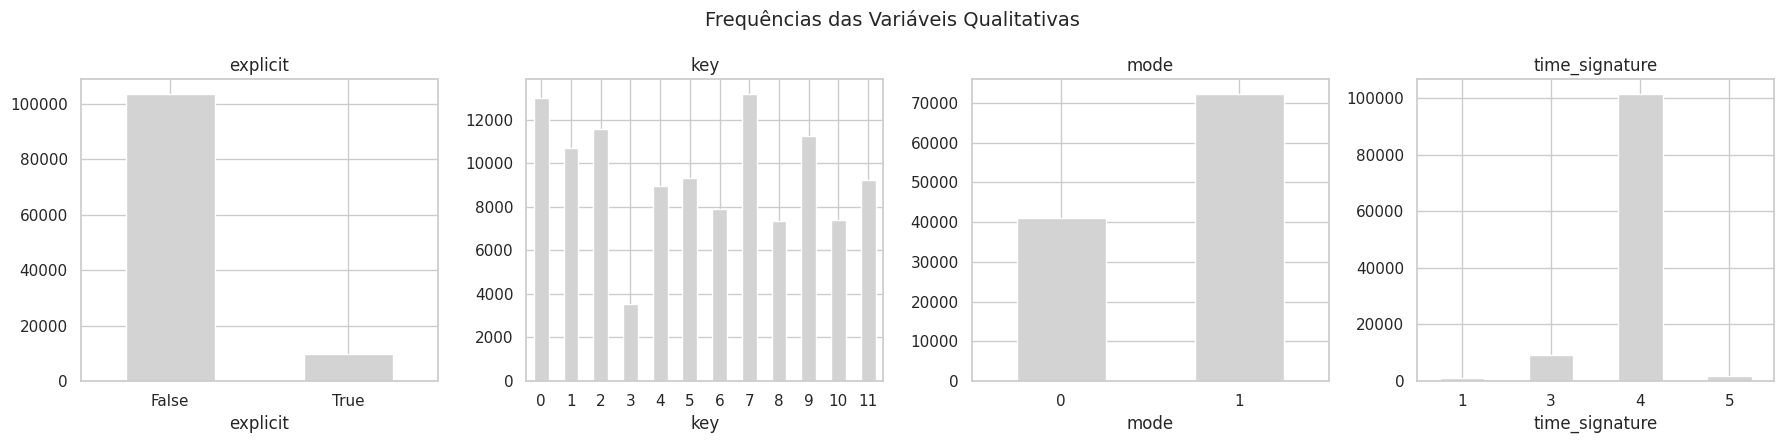

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

for i, col in enumerate(VARS_QUALI):
    df[col].value_counts().sort_index().plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=0)

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

**Discussão:** dois graus muito diferentes de desbalanceamento.

- `time_signature` é dominada por compasso 4 (~90%), o que é simplesmente como a música popular ocidental funciona. O desbalanceamento aqui é a realidade do domínio, não um defeito da amostra.
- `explicit` tem 91,5% de faixas não-explícitas, razão de 10,7 para 1.
- `key` é a mais equilibrada das quatro — as 12 tonalidades aparecem em proporções parecidas, com leve preferência por C, G e D, que são as tonalidades mais confortáveis em violão e piano.
- `mode` fica em 64% maior / 36% menor, também coerente com o repertório popular.

Para `explicit` e `time_signature`, o desbalanceamento importa na leitura dos cruzamentos: a categoria minoritária tem poucos casos e qualquer proporção calculada sobre ela é mais instável.

### Popularidade por gênero — com e sem os zeros suspeitos

**Escolha da visualização.** A pergunta aqui não é "qual gênero é mais popular", e sim **quanto a decisão de tratamento muda a resposta** — é uma comparação pareada entre dois cenários para as mesmas categorias.

Isso pede **barras agrupadas**: as duas versões do mesmo gênero ficam adjacentes, e a diferença entre elas é lida diretamente como diferença de altura. Duas alternativas foram descartadas: barras empilhadas (não faz sentido, os valores não somam), e dois gráficos separados (obrigaria o leitor a alternar entre eles e comparar de memória).

Mostramos os **10 maiores e 10 menores**, ordenados pela versão corrigida, para que o contraste apareça nos dois extremos. Usamos **mediana** e não média porque `popularity` tem 14% de zeros suspeitos, e a média seria arrastada por eles justamente nos gêneros que queremos avaliar.

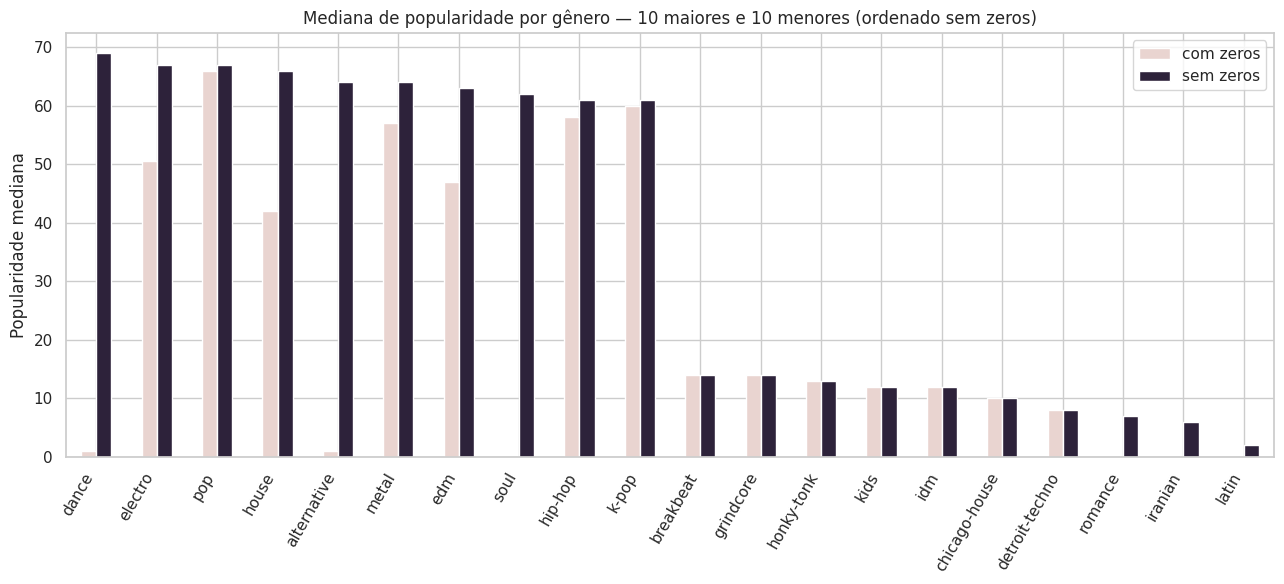

In [ ]:
mediana_completa = df.groupby("track_genre")["popularity"].median()
mediana_valida = df_pop_valida.groupby("track_genre")["popularity"].median()

ordem = mediana_valida.sort_values(ascending=False)
sel = pd.concat([ordem.head(10), ordem.tail(10)]).index

comp = pd.DataFrame({"com zeros": mediana_completa[sel], "sem zeros": mediana_valida[sel]})

fig, ax = plt.subplots(figsize=(13, 6))
comp.plot(kind="bar", color=[COR_CONTEXTO, COR_DESTAQUE], ax=ax)
ax.set_title("Mediana de popularidade por gênero — 10 maiores e 10 menores (ordenado sem zeros)")
ax.set_ylabel("Popularidade mediana")
ax.set_xlabel("")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

**Discussão — por que a decisão da Seção 4 importava.**

O contraste entre as duas barras mostra o estrago que os zeros fariam se fossem tratados como dado válido. Sete gêneros aparecem com mediana **zero** na base completa, e as suas medianas reais são: `soul` 62, `rock` 47, `country` 44, `jazz` 41. O caso de `soul` é o mais extremo — é o 8º gênero mais popular da base entre as faixas efetivamente medidas, e apareceria no fundo absoluto do ranking se os zeros fossem tratados como audiência real. A conclusão "jazz e soul são os gêneros menos populares do Spotify" seria uma afirmação puramente sobre falha de coleta.

Alguns resultados sobrevivem aos dois recortes: `pop`, `hip-hop`, `k-pop` e `metal` aparecem no topo de qualquer maneira. Esses são os achados confiáveis, porque são robustos à decisão de tratamento. Já `dance`, `electro` e `house`, que lideram o ranking corrigido, sequer apareciam entre os primeiros na base bruta.

**Lição de método:** quando uma conclusão muda dependendo de como tratamos os dados faltantes, ela não é uma conclusão sobre o fenômeno — é uma conclusão sobre a nossa escolha de tratamento. Rodar nos dois recortes é o que permite distinguir uma coisa da outra.

### Desbalanceamento entre classes

In [ ]:
def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_norm = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({"n_classes": n_classes,
                      "razao_desbalanceamento": round(razao, 2),
                      "entropia_normalizada": round(ent_norm, 3)})

vars_para_checar = VARS_QUALI + ["track_genre", "faixa_pop"]
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
explicit,2.0,10.67,0.422
key,12.0,3.72,0.983
mode,2.0,1.76,0.944
time_signature,4.0,104.95,0.295
track_genre,114.0,1.16,1.000
faixa_pop,2.0,2.87,0.825


**Discussão:** `time_signature` tem entropia 0,295 e razão de 105 para 1 — a mais desbalanceada. `explicit` fica em 0,422.

O caso de `track_genre` é o mais revelador: **entropia normalizada 1,000**, o máximo possível. Uma variável com 114 categorias perfeitamente equilibradas não acontece em dado observacional — é a assinatura matemática da amostragem estratificada que identificamos na Seção 1. O que em outro contexto seria uma boa notícia ("classes balanceadas!") aqui é um alerta: o balanceamento é artificial.

`faixa_pop` fica em 0,825 (razão 2,87 para 1), aceitável para as comparações bivariadas adiante.

### Análise Bivariada

#### Quantitativa x Quantitativa — Correlação

**Escolha da visualização e do coeficiente.** Conhecemos três coeficientes: Pearson (linear, exige normalidade, sensível a outliers), Spearman e Kendall (monotônicos, não exigem normalidade). A Seção 3 mostrou que **nenhuma** das 11 variáveis passou no teste de normalidade, e várias têm caudas pesadas — `speechiness` com curtose 28,8, `duration_ms` com 334. Pearson é tecnicamente inadequado aqui, e Kendall, embora válido, responde à mesma pergunta que Spearman com custo computacional muito maior em 113 mil linhas. **Usamos um único gráfico, com Spearman.**

Sobre o formato: matriz de correlação como **heatmap com triângulo inferior**. O heatmap é a escolha natural para 11 x 11 = 121 pares — uma tabela numérica exigiria leitura célula a célula, enquanto a cor permite localizar os pares fortes de relance. Mascaramos o triângulo superior porque a matriz é simétrica: mostrar os dois lados duplica a informação e dobra a carga visual sem acrescentar nada.

A comparação entre coeficientes continua sendo feita, mas como **tabela** em vez de três gráficos lado a lado — o que interessa ali são poucos números (onde Pearson e Spearman divergem), e não a matriz inteira repetida três vezes.

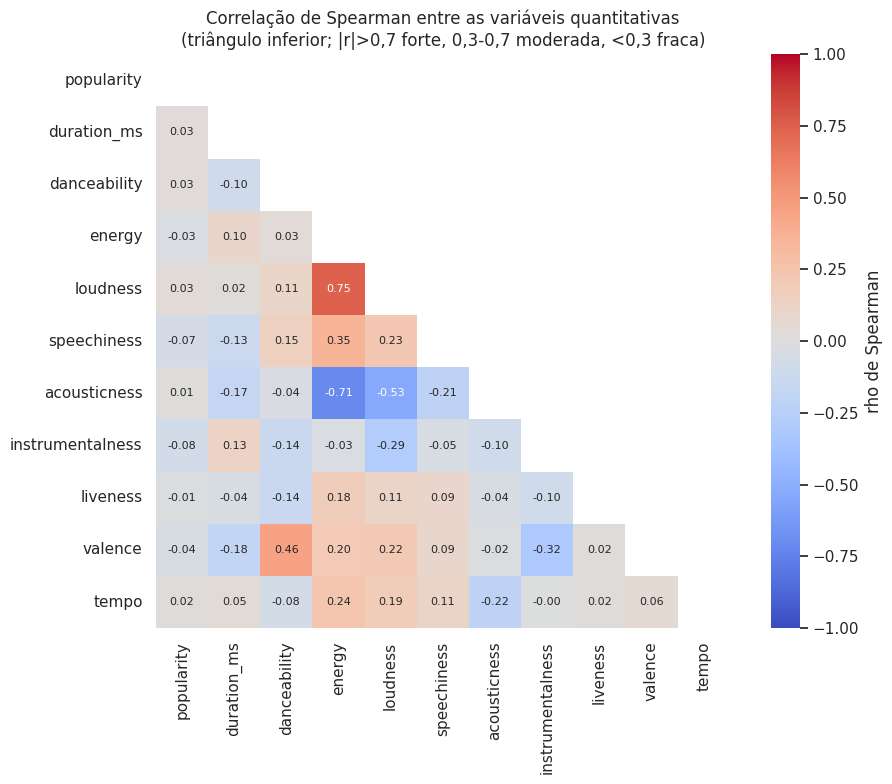

In [ ]:
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_pearson = df[VARS_QUANT].corr(method="pearson")

mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(10, 8))
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f",
            square=True, vmin=-1, vmax=1, annot_kws={"size": 8},
            cbar_kws={"label": "rho de Spearman"})
plt.title("Correlação de Spearman entre as variáveis quantitativas\n(triângulo inferior; |r|>0,7 forte, 0,3-0,7 moderada, <0,3 fraca)")
plt.grid(False)
plt.tight_layout()
plt.show()

In [ ]:
divergencia = (corr_pearson - corr_spearman).abs().where(~mask).stack().sort_values(ascending=False)

tabela_div = pd.DataFrame({
    "pearson": [corr_pearson.loc[a, b] for a, b in divergencia.index[:6]],
    "spearman": [corr_spearman.loc[a, b] for a, b in divergencia.index[:6]],
    "diferença": divergencia.values[:6],
}, index=[f"{a} x {b}" for a, b in divergencia.index[:6]]).round(3)

print("Pares onde Pearson e Spearman mais divergem:")
display(tabela_div)

Pares onde Pearson e Spearman mais divergem:


,pearson,spearman,diferença
acousticness x speechiness,-0.001,-0.214,0.213
speechiness x energy,0.140,0.353,0.213
instrumentalness x acousticness,0.101,-0.100,0.201
speechiness x loudness,0.058,0.229,0.172
instrumentalness x energy,-0.177,-0.031,0.146
instrumentalness x loudness,-0.431,-0.286,0.145


**Discussão:** três correlações se destacam, e todas têm explicação física direta:

- **`energy` x `loudness` = +0,75** — a mais forte da base. Faixas mais intensas são masterizadas mais alto; é essencialmente a "loudness war" da indústria fonográfica aparecendo no dado.
- **`acousticness` x `energy` = -0,71** — gravação acústica e alta energia são quase mutuamente exclusivas.
- **`acousticness` x `loudness` = -0,53** — mesma lógica, via o elo anterior.

Esse trio forma um bloco redundante: as três medem, de ângulos diferentes, a mesma dimensão "intensidade sonora". Em uma modelagem posterior isso seria multicolinearidade e pediria seleção de variável ou redução de dimensionalidade.

Uma quarta correlação é mais interessante conceitualmente: **`valence` x `danceability` = +0,46**. Música alegre tende a ser mais dançante — moderado, mas consistente, e é um dos poucos pares em que a relação é de conteúdo e não de engenharia de áudio.

**Pearson x Spearman divergem em algum par?** As maiores divergências estão em `speechiness` x `energy` (0,21 de diferença), `acousticness` x `speechiness` (0,21) e `instrumentalness` x `acousticness` (0,20) — todas envolvendo as variáveis mais assimétricas. Isso confirma o que se esperava: onde a distribuição tem cauda pesada, Pearson é puxado pelos extremos e Spearman, que trabalha com postos, não é. Nesses pares, o valor de Spearman é o confiável.

**O que não aparece:** `popularity` não tem correlação relevante com **nenhuma** audio feature — todos os coeficientes ficam abaixo de 0,1 em módulo. Este é o resultado central da EDA e é respondido na pergunta 1: nenhuma característica sonora isolada prevê popularidade.

#### Dispersão entre duas variáveis quantitativas

**Escolha da visualização.** A matriz de correlação dá um número por par; o **scatter** mostra o formato da relação, que o coeficiente resume e às vezes distorce. Escolhemos `energy` x `loudness` por dois critérios convergentes: é o maior |rho| da base (0,75) e tem explicação de domínio (faixas mais intensas são masterizadas mais alto).

Duas decisões impostas pelo volume de dados. Usamos uma **amostra de 6.000 faixas**: com 113 mil pontos, o scatter satura e vira uma mancha sólida, escondendo densidade e estrutura. E aplicamos **transparência** (`alpha=0.6`) com pontos pequenos, para que regiões de sobreposição fiquem visualmente mais escuras e a densidade seja legível mesmo na amostra. A cor codifica a classe de popularidade, reaproveitando a convenção do notebook — o que permite responder, no mesmo gráfico, se as classes ocupam regiões distintas do plano.

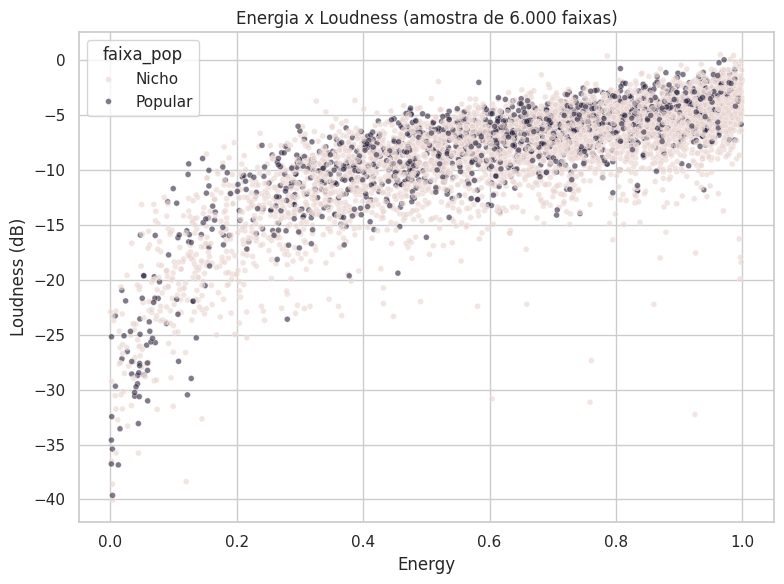

In [ ]:
amostra_plot = df.sample(6000, random_state=42)

plt.figure(figsize=(8, 6))
sns.scatterplot(data=amostra_plot, x="energy", y="loudness", hue="faixa_pop",
                palette={"Nicho": COR_CONTEXTO, "Popular": COR_DESTAQUE}, alpha=0.6, s=18)
plt.title("Energia x Loudness (amostra de 6.000 faixas)")
plt.xlabel("Energy")
plt.ylabel("Loudness (dB)")
plt.tight_layout()
plt.show()

**Discussão:** escolhemos esse par por motivo de domínio (a relação entre intensidade percebida e volume de masterização), reforçado por ser o maior |r| da matriz. A tendência crescente é nítida, e o formato é informativo: a nuvem é **heterocedástica** — apertada e quase linear na região de alta energia, e muito mais dispersa embaixo, onde faixas de baixa energia aparecem com volumes que vão de -45 a -10 dB. Ou seja, alta energia praticamente garante volume alto, mas baixa energia não determina nada.

Usamos amostra de 6.000 pontos porque, com 113 mil, o scatter vira uma mancha sólida e a estrutura desaparece. Quanto às cores: as duas classes estão **completamente misturadas**, sem região própria. Compare com o exemplo do Heart Disease em aula, em que as classes ocupavam regiões distintas do plano — aqui, mais uma evidência visual de que popularidade não se separa por audio features.

#### Quantitativa x Qualitativa — comparando grupos

T-test e ANOVA assumem normalidade dentro de cada grupo, e a Seção 3 já mostrou que nenhuma variável atende a isso. Usamos **Mann-Whitney U** como resultado principal e o t-test como contraste, seguindo a aula.

Acrescentamos uma coluna que a aula não tinha, mas que é indispensável aqui: o **tamanho de efeito** (correlação rank-biserial, derivada do próprio U). Com n = 113 mil, o p-valor perde quase toda a capacidade de discriminar — praticamente qualquer diferença vira "significativa". O tamanho de efeito responde a pergunta que o p-valor não responde: *a diferença é grande?*

In [ ]:
resultados_comparacao = []
for col in [c for c in VARS_QUANT if c != "popularity"]:
    g_nicho = df.loc[df["faixa_pop"] == "Nicho", col]
    g_pop = df.loc[df["faixa_pop"] == "Popular", col]

    stat_t, p_t = stats.ttest_ind(g_nicho, g_pop, equal_var=False)
    stat_u, p_u = stats.mannwhitneyu(g_nicho, g_pop)
    rank_biserial = 1 - 2 * stat_u / (len(g_nicho) * len(g_pop))

    resultados_comparacao.append({
        "variavel": col,
        "mediana_Nicho": round(g_nicho.median(), 3),
        "mediana_Popular": round(g_pop.median(), 3),
        "p_ttest": f"{p_t:.2g}",
        "p_mannwhitney": f"{p_u:.2g}",
        "rank_biserial": round(rank_biserial, 3),
        "significativo": p_u < 0.05,
    })

pd.DataFrame(resultados_comparacao).set_index("variavel").sort_values("rank_biserial", key=abs, ascending=False)

,mediana_Nicho,mediana_Popular,p_ttest,p_mannwhitney,rank_biserial,significativo
variavel,,,,,,
liveness,0.136,0.124,2.6e-245,2.5e-88,-0.078,True
instrumentalness,0.000,0.000,1.4e-180,1.8e-66,-0.066,True
valence,0.477,0.435,5.6e-69,1.6e-58,-0.063,True
speechiness,0.050,0.047,4.6e-104,1.3e-53,-0.060,True
loudness,-7.099,-6.690,6e-24,2.7e-48,0.057,True
danceability,0.577,0.591,1.7e-64,2.1e-44,0.055,True
energy,0.693,0.668,7.9e-22,1.1e-39,-0.052,True
duration_ms,214014.500,210955.500,2.2e-64,4.6e-18,-0.034,True
tempo,122.559,121.225,2.9e-06,1.7e-06,-0.019,True


**Discussão — significância estatística não é relevância prática.**

Os dois testes concordam: **todas as dez variáveis dão p < 0,05**, várias com p na casa de 10^-88. Se parássemos aqui, a conclusão seria "todas as audio features diferenciam faixas populares de faixas de nicho".

A coluna de tamanho de efeito desmonta essa leitura. O maior |rank-biserial| da tabela é **0,078** (`liveness`) — a convenção usual trata 0,1 como efeito pequeno, então estamos abaixo até do piso do "pequeno". Traduzindo `liveness`: mediana 0,136 no grupo Nicho contra 0,124 no Popular. É uma diferença de 0,012 em uma escala de 0 a 1, detectada com p = 2,5 x 10^-88 unicamente porque há 113 mil observações para dar poder ao teste.

O padrão das diferenças, ainda que minúsculo, é coerente: faixas populares são marginalmente menos "ao vivo" (-0,078), menos faladas (-0,060), menos instrumentais (-0,066), levemente mais dançantes (+0,055) e mais altas (+0,057). Descreve produção de estúdio polida — mas o efeito é fraco demais para sustentar previsão.

**Sobre a divergência entre os testes:** t-test e Mann-Whitney concordam em todas as variáveis quanto à decisão, mas discordam bastante em *magnitude* de p. Em `instrumentalness`, o t-test dá 10^-180 contra 10^-66 do Mann-Whitney. O t-test compara médias de uma variável com 34% das observações empilhadas em zero — exatamente o cenário em que a premissa de normalidade falha e o p-valor fica inflado. **Reportamos o Mann-Whitney como principal.**

**Escolha da visualização.** Comparar uma variável quantitativa entre 114 grupos exige mostrar **a distribuição dentro de cada grupo**, não só uma medida-resumo. Barras com a mediana esconderiam a dispersão interna — e é justamente ela que sustenta a ressalva mais importante desta seção: o gênero desloca a popularidade, mas não determina o destino de uma faixa individual.

**Boxplot** é a escolha aqui, e não violin: com 16 gêneros lado a lado, violinos ficariam estreitos demais para que a forma fosse legível, enquanto caixa, mediana e hastes permanecem comparáveis mesmo em painel apertado. Mostramos **8 maiores e 8 menores** por mediana, na base sem os zeros suspeitos pelos motivos da Seção 4.

ANOVA          — popularidade entre gêneros: estatística=526.3, p-valor=0
Kruskal-Wallis — popularidade entre gêneros: estatística=40362.1, p-valor=0


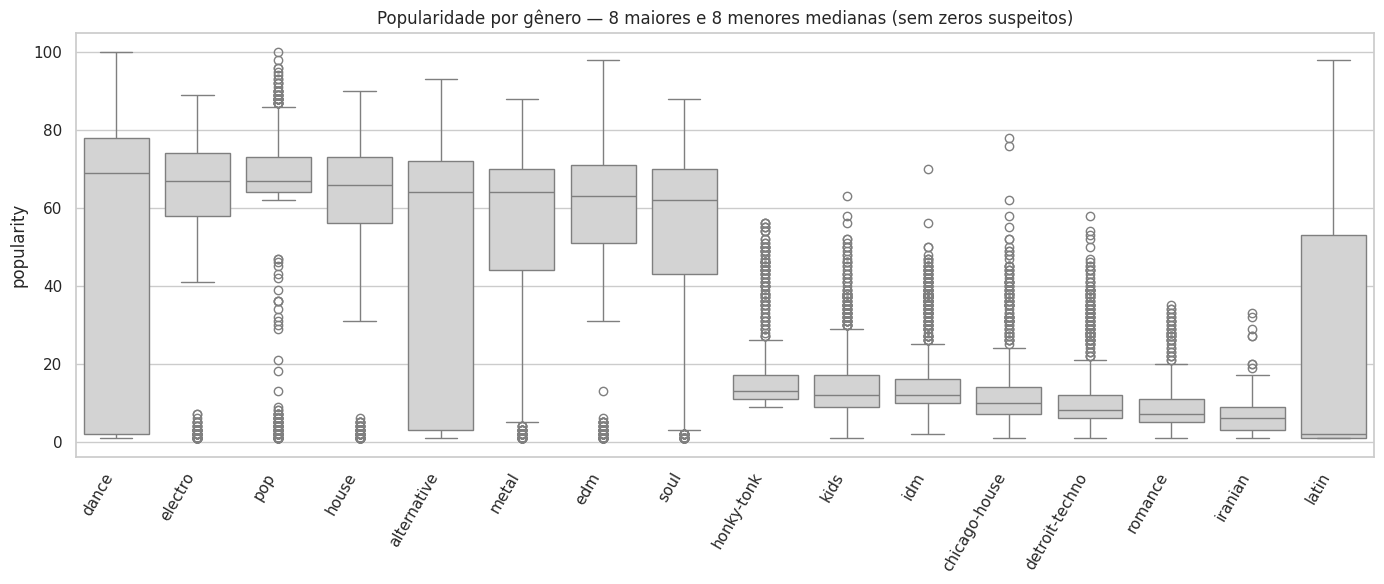

In [ ]:
grupos_genero = [g["popularity"].values for _, g in df_pop_valida.groupby("track_genre")]

stat_anova, p_anova = stats.f_oneway(*grupos_genero)
stat_kw, p_kw = stats.kruskal(*grupos_genero)

print(f"ANOVA          — popularidade entre gêneros: estatística={stat_anova:.1f}, p-valor={p_anova:.3g}")
print(f"Kruskal-Wallis — popularidade entre gêneros: estatística={stat_kw:.1f}, p-valor={p_kw:.3g}")

top_generos = df_pop_valida.groupby("track_genre")["popularity"].median().sort_values(ascending=False)
sel = list(top_generos.head(8).index) + list(top_generos.tail(8).index)

plt.figure(figsize=(14, 6))
sns.boxplot(data=df_pop_valida[df_pop_valida["track_genre"].isin(sel)],
            x="track_genre", y="popularity", order=sel, color=COR_NEUTRA)
plt.title("Popularidade por gênero — 8 maiores e 8 menores medianas (sem zeros suspeitos)")
plt.xticks(rotation=60, ha="right")
plt.xlabel("")
plt.tight_layout()
plt.show()

**Discussão:** os dois testes rejeitam a hipótese de igualdade com folga, e como `popularity` não é normal, **Kruskal-Wallis é o resultado a reportar**. A ANOVA fica como contraste pedagógico.

Mais interessante que o p-valor é o contraste com a seção anterior. As audio features quase não diferenciam popularidade (efeitos < 0,08); o **gênero**, sim — a distância entre a mediana de `pop` e a dos gêneros no fim da lista é de dezenas de pontos, uma diferença de ordem de grandeza completamente distinta.

A leitura conjunta responde à pergunta 1 desta EDA: **o que mais explica popularidade neste dataset não é como a música soa, é a que categoria ela pertence.** Dito de outro modo, popularidade parece ser mais função de distribuição, curadoria e algoritmo de recomendação do que de propriedades acústicas — o que faz sentido, já que o próprio índice de popularidade do Spotify é calculado a partir de reproduções recentes, não de áudio.

**Ressalva importante:** os boxplots mostram caixas muito largas *dentro* de cada gênero. Mesmo em `pop`, há faixas cobrindo quase toda a escala. O gênero desloca a distribuição, mas está longe de determinar o resultado de uma faixa individual.

**Escolha da visualização.** São duas perguntas diferentes sobre o mesmo cruzamento, e cada uma pede uma codificação.

O **heatmap de contingência** mostra as contagens absolutas, e importa porque `explicit` é muito desbalanceada (9.747 faixas contra 104.253) — qualquer proporção calculada sobre a categoria minoritária precisa ser lida sabendo quantos casos a sustentam. Já as **barras empilhadas normalizadas** mostram a proporção dentro de cada categoria, que é a comparação de interesse e que as contagens brutas tornariam impossível de enxergar.

Por isso os dois aparecem lado a lado: não é a mesma informação duas vezes, é contagem e proporção, que respondem a perguntas distintas e seriam enganosas isoladamente.

,chi2,gl,p_valor,V_cramer
variavel,,,,
explicit,373.7,1,3e-83,0.057
key,205.4,11,5.6e-38,0.043
mode,73.4,1,1.1e-17,0.025
time_signature,163.6,3,3.1e-35,0.038


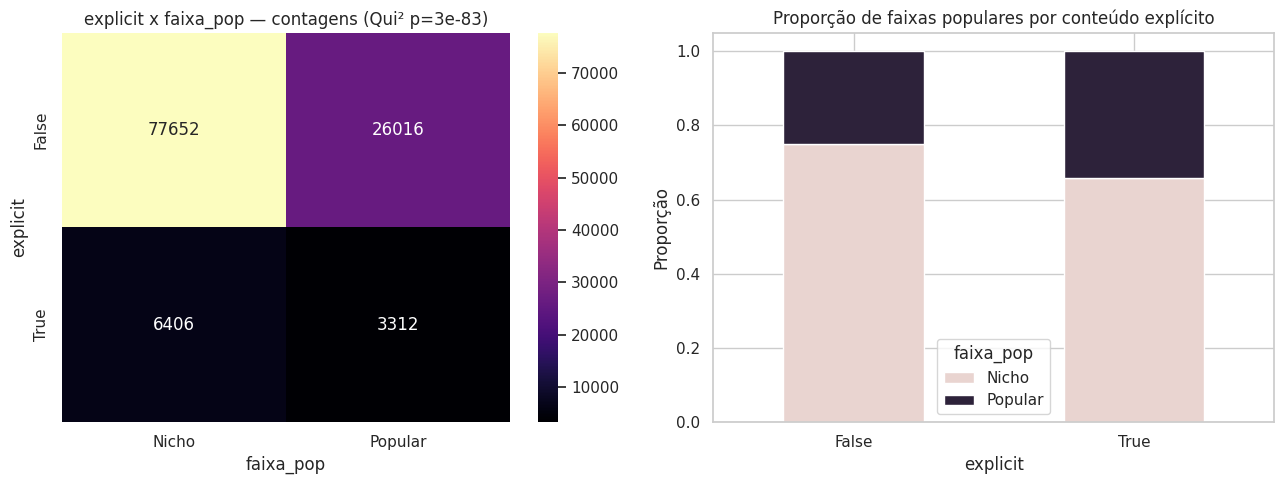

In [ ]:
resultados_chi2 = []
for col in VARS_QUALI:
    contingencia = pd.crosstab(df[col], df["faixa_pop"])
    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)
    n = contingencia.values.sum()
    v_cramer = np.sqrt(chi2 / (n * (min(contingencia.shape) - 1)))
    resultados_chi2.append({"variavel": col, "chi2": round(chi2, 1), "gl": gl,
                            "p_valor": f"{p_valor:.2g}", "V_cramer": round(v_cramer, 3)})

display(pd.DataFrame(resultados_chi2).set_index("variavel"))

contingencia_expl = pd.crosstab(df["explicit"], df["faixa_pop"])
chi2_e, p_e, gl_e, esp_e = stats.chi2_contingency(contingencia_expl)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(contingencia_expl, annot=True, fmt="d", cmap="magma", ax=axes[0])
axes[0].set_title(f"explicit x faixa_pop — contagens (Qui² p={p_e:.3g})")

pd.crosstab(df["explicit"], df["faixa_pop"], normalize="index").plot(
    kind="bar", stacked=True, color=[COR_CONTEXTO, COR_DESTAQUE], ax=axes[1])
axes[1].set_title("Proporção de faixas populares por conteúdo explícito")
axes[1].set_ylabel("Proporção")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Discussão:** as quatro variáveis dão p muito abaixo de 0,05, mas o V de Cramér fica entre **0,025 e 0,057** — associações que, pela convenção usual, são desprezíveis (abaixo de 0,1).

`explicit` é a mais forte das quatro, e ainda assim com V = 0,057. Em termos concretos: **34,1% das faixas explícitas são populares, contra 25,1% das não-explícitas**. A diferença de 9 pontos é real e vale mencionar, mas está longe de fazer de `explicit` um preditor útil — e provavelmente é mediada por gênero (hip-hop concentra faixas explícitas *e* aparece entre os gêneros de maior popularidade), e não uma relação direta.

Mesmo padrão da seção anterior: p-valores astronômicos, efeitos desprezíveis. Com bases desse tamanho, reportar Qui-Quadrado sem tamanho de efeito produz uma lista de "associações significativas" que não significam quase nada na prática.

**Escolha da visualização.** Cada ponto é um gênero, e a pergunta é sobre a **relação entre duas medidas contínuas** calculadas por gênero — o que pede scatter, não barras.

São dois painéis porque são dois argumentos distintos. O da **esquerda** cruza proporção de zeros com popularidade real e mostra a direção do viés: a falha de coleta atingiu os gêneros mais populares, não os menos. O da **direita** compara a mediana nos dois cenários e inclui uma **linha diagonal de referência**: gêneros sobre a linha não foram afetados, e os que se afastam dela para o eixo Y são os que colapsam para zero na base bruta. A diagonal é o elemento que torna o desvio legível sem cálculo mental.

Com 114 pontos, o scatter não satura e dispensa amostragem ou transparência.

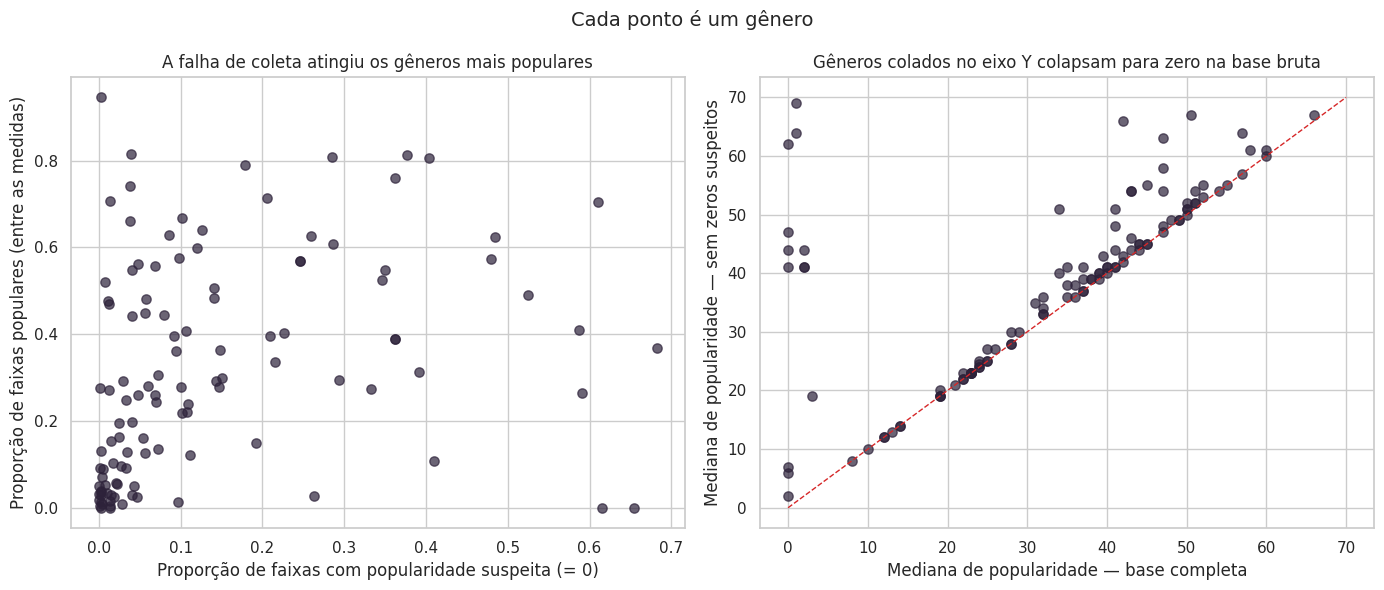

rho(proporção de zeros, proporção de populares SEM zeros) = +0.477  (p=7.99e-08)
rho(proporção de zeros, proporção de populares COM zeros) = +0.322  (p=0.000467)

Gêneros com mediana zero na base completa: 7


In [ ]:
por_genero = pd.DataFrame({
    "prop_zeros": df.groupby("track_genre")["pop_suspeita"].mean(),
    "mediana_com_zeros": df.groupby("track_genre")["popularity"].median(),
    "mediana_sem_zeros": df_pop_valida.groupby("track_genre")["popularity"].median(),
    "prop_popular_sem_zeros": df_pop_valida.groupby("track_genre")["faixa_pop"].apply(lambda s: (s == "Popular").mean()),
})

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].scatter(por_genero["prop_zeros"], por_genero["prop_popular_sem_zeros"],
                color=COR_DESTAQUE, alpha=0.7, s=45)
axes[0].set_xlabel("Proporção de faixas com popularidade suspeita (= 0)")
axes[0].set_ylabel("Proporção de faixas populares (entre as medidas)")
axes[0].set_title("A falha de coleta atingiu os gêneros mais populares")

axes[1].scatter(por_genero["mediana_com_zeros"], por_genero["mediana_sem_zeros"],
                color=COR_DESTAQUE, alpha=0.7, s=45)
axes[1].plot([0, 70], [0, 70], color=COR_ALERTA, linestyle="--", linewidth=1)
axes[1].set_xlabel("Mediana de popularidade — base completa")
axes[1].set_ylabel("Mediana de popularidade — sem zeros suspeitos")
axes[1].set_title("Gêneros colados no eixo Y colapsam para zero na base bruta")

fig.suptitle("Cada ponto é um gênero", fontsize=14)
plt.tight_layout()
plt.show()

r1 = stats.spearmanr(por_genero["prop_zeros"], por_genero["prop_popular_sem_zeros"])
r2 = stats.spearmanr(por_genero["prop_zeros"], df.groupby("track_genre")["faixa_pop"].apply(lambda s: (s == "Popular").mean()))
print(f"rho(proporção de zeros, proporção de populares SEM zeros) = {r1.statistic:+.3f}  (p={r1.pvalue:.3g})")
print(f"rho(proporção de zeros, proporção de populares COM zeros) = {r2.statistic:+.3f}  (p={r2.pvalue:.3g})")
print(f"\nGêneros com mediana zero na base completa: {int((por_genero['mediana_com_zeros'] == 0).sum())}")

**Discussão — o viés não é aleatório, e sua direção é a pior possível.**

A correlação entre "quanto um gênero foi afetado pela falha de coleta" e "quão popular esse gênero realmente é" é **+0,48**. A falha de coleta **não foi aleatória entre gêneros: ela atingiu justamente os gêneros mais populares** — jazz, rock, soul, country, alternative, que são categorias mainstream com grande audiência, perderam de 48% a 68% das medições, enquanto nichos como honky-tonk, detroit-techno e forró saíram praticamente ilesos.

O efeito no ranking é uma inversão. Como os zeros entram na conta como se fossem audiência zero, os gêneros mais atingidos — que são os mais populares — despencam para o fundo da lista. O painel da direita mostra isso geometricamente: os pontos colados no eixo Y são gêneros cuja mediana real vai de 41 a 62, mas que a base bruta registra como zero.

Isso responde à pergunta 3 desta EDA, e é a razão pela qual a Seção 4 rejeitou tanto remover quanto imputar os zeros — as duas opções teriam escondido essa relação em vez de revelá-la.

**Analogia com a discussão de fairness da aula:** lá, a pergunta era se a taxa de diagnóstico variava entre sexo e faixa etária, e se isso refletia risco clínico real ou viés de encaminhamento. Aqui a estrutura lógica é idêntica: a taxa de popularidade varia muito entre gêneros, e parte substancial dessa variação é artefato de coleta, não fenômeno musical. Um teste estatístico aponta *que* existe associação, nunca *a causa* dela — e neste caso, investigar a causa foi o que impediu uma conclusão completamente errada.

**Limitação que fica registrada:** como não há dados de artista, país, gravadora ou ouvinte, não é possível avaliar vieses de representatividade mais profundos (de gênero do artista, de origem geográfica, de tamanho de gravadora) que a literatura documenta em catálogos de streaming. É uma limitação do dataset, não da análise.

#### Outliers bivariados

**Escolha da visualização.** Um ponto pode ser perfeitamente comum em cada variável isoladamente e anômalo na **combinação** das duas — e nenhum gráfico univariado detecta isso. O `jointplot` é a escolha porque põe as três vistas necessárias na mesma figura: o scatter conjunto no centro e as duas distribuições marginais nas bordas.

Isso é o que permite o argumento desta seção: verificar nas marginais que 180 BPM e dançabilidade 0,3 são valores individualmente normais, e ver no centro que a combinação dos dois é rara. Dois gráficos separados exigiriam do leitor cruzar essa informação de memória.

Mesmas decisões de volume do scatter anterior — amostra de 6.000 faixas e transparência —, pelo mesmo motivo de saturação.

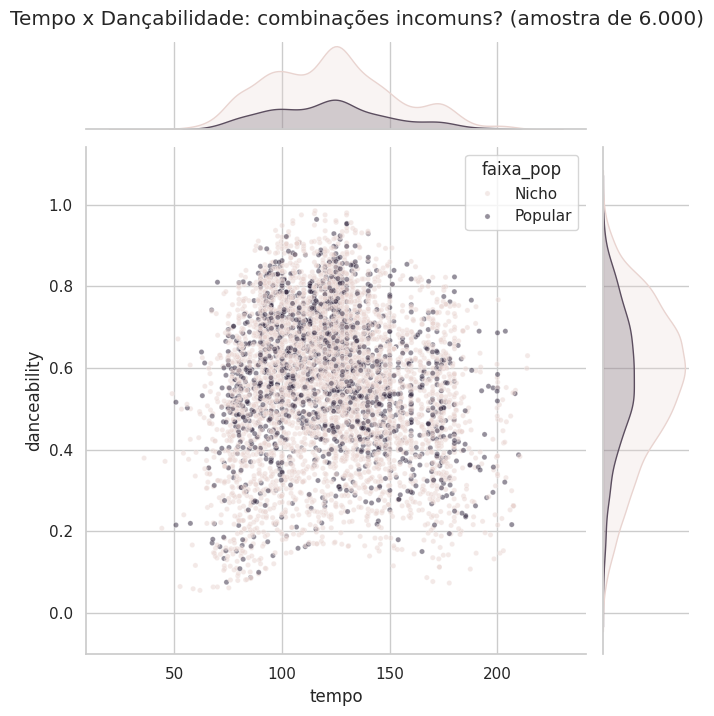

In [ ]:
sns.jointplot(data=amostra_plot, x="tempo", y="danceability", hue="faixa_pop",
              palette={"Nicho": COR_CONTEXTO, "Popular": COR_DESTAQUE}, alpha=0.5, height=7, s=14)
plt.suptitle("Tempo x Dançabilidade: combinações incomuns? (amostra de 6.000)", y=1.02)
plt.show()

**Discussão:** as marginais mostram `tempo` com picos em 120, 140 e 170 BPM — grades rítmicas típicas de produção eletrônica e de programas de DAW — e `danceability` bem comportada em torno de 0,58. Individualmente, nenhum ponto chama atenção.

A região interessante é o canto **inferior direito**: faixas acima de 180 BPM com dançabilidade abaixo de 0,3. Em nenhum histograma univariado esses pontos apareceriam como outliers (180 BPM é normal, 0,3 de dançabilidade é normal), mas a **combinação** é incomum — tempo muito rápido com pulso pouco dançante. É o perfil de metal extremo, drum and bass e faixas de música clássica rápida, que a análise univariada não teria encontrado. É exatamente o argumento da detecção bivariada.

#### Análise Multivariada

A matriz de correlação da seção anterior já respondeu à pergunta "quais pares se relacionam". A pergunta multivariada é outra: **o formato dessas relações é o que o coeficiente sugere?** Um rho de 0,75 pode vir de uma reta limpa ou de uma nuvem com estrutura interna que o número esconde.

**Escolha da visualização:** o correlograma responde a isso com um gráfico só, combinando três camadas — dispersão no triângulo inferior (o formato), coeficiente no superior (a força, com tamanho e cor do círculo redundantes para leitura rápida) e distribuição na diagonal. Repetir o heatmap aqui não acrescentaria nada, já que ele mostra exatamente a mesma informação da seção anterior.

Limitamos a 5 variáveis e a uma amostra de 3.000 faixas: com 11 variáveis seriam 121 painéis ilegíveis, e com 113 mil pontos cada dispersão viraria uma mancha sólida.

##### Correlograma

**Escolha da visualização.** A matriz de correlação da seção anterior já respondeu *quais* pares se relacionam. A pergunta multivariada é outra: **o formato dessas relações é o que o coeficiente sugere?** Um rho de 0,75 pode vir de uma reta limpa ou de uma nuvem com estrutura interna que o número esconde.

O **correlograma** responde a isso em um gráfico só, combinando três camadas: dispersão no triângulo inferior (o formato), coeficiente no superior (a força, com tamanho e cor do círculo codificando o mesmo valor de forma redundante, para leitura rápida) e distribuição na diagonal. Repetir o heatmap aqui não acrescentaria nada — mostraria exatamente a mesma informação da seção anterior.

Duas restrições impostas pelo dataset: limitamos a **5 variáveis** (com 11 seriam 121 painéis ilegíveis) e a uma **amostra de 3.000 faixas** (com 113 mil, cada dispersão viraria mancha sólida).

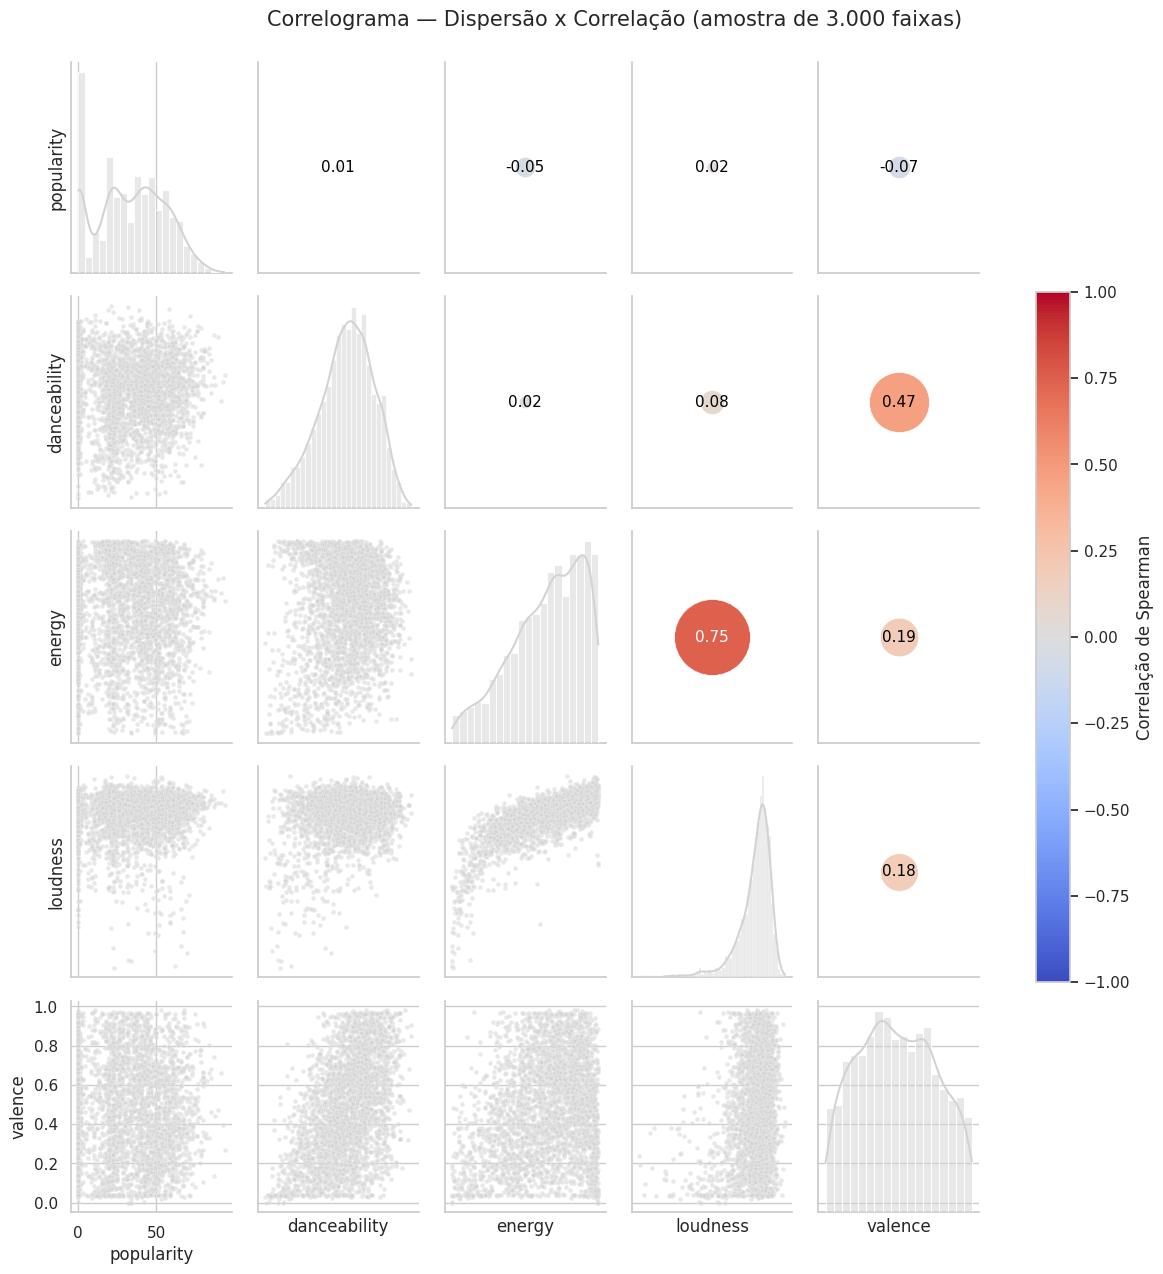

In [ ]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

VARS_CORRELOGRAMA = ["popularity", "danceability", "energy", "loudness", "valence"]
amostra_corr = df[VARS_CORRELOGRAMA].sample(3000, random_state=42)

def circulo_correlacao(x, y, **kwargs):
    r = stats.spearmanr(x, y).statistic
    ax = plt.gca()
    ax.scatter([0.5], [0.5], s=abs(r) * 4000, c=[r], cmap="coolwarm", vmin=-1, vmax=1,
               transform=ax.transAxes, edgecolor="white", linewidth=0.5)
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes, ha="center", va="center",
                fontsize=11, color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

g = sns.PairGrid(amostra_corr, diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.5, s=12)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

sm = ScalarMappable(norm=Normalize(-1, 1), cmap="coolwarm")
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação de Spearman")
g.fig.suptitle("Correlograma — Dispersão x Correlação (amostra de 3.000 faixas)", y=1.02, fontsize=15)
plt.show()

**Discussão:** o correlograma resume visualmente o que a EDA inteira vem mostrando. A linha e a coluna de `popularity` são o ponto a observar: **todos os círculos são minúsculos e quase brancos**, e todos os scatters formam nuvens sem direção. Em contraste, `energy` x `loudness` aparece com um círculo grande e vermelho, e o scatter correspondente mostra uma tendência clara.

A diagonal também é informativa: `popularity` tem o formato achatado com o pico residual em zero, `valence` é quase uniforme, `loudness` é a mais assimétrica das cinco.

## 7. Síntese — Principais Conclusões

**1. O dataset não é uma amostra do Spotify; é uma amostra estratificada com 1.000 faixas por gênero.** A entropia normalizada de `track_genre` é exatamente 1,000 nos 114 gêneros. Isso invalida qualquer conclusão sobre *prevalência* ("X% das músicas do Spotify são Y") e é a limitação mais importante a declarar em qualquer uso posterior desta base. A documentação, além disso, anuncia 125 gêneros — são 114.

**2. Cerca de 14% das faixas têm popularidade zero, e esses zeros são dados ausentes disfarçados.** Eles se concentram em gêneros inteiros (68% do jazz, 61% de soul, 59% de country, contra ~0% de forró e honky-tonk), padrão sem explicação musical possível — e, pior, concentram-se justamente nos gêneros de maior audiência real. O mecanismo mais plausível é MAR condicional ao gênero: falha de coleta em lotes. Optamos por marcar e segmentar em vez de remover ou imputar, porque remover teria descartado dados de forma enviesada e imputar teria fabricado o próprio resultado que queríamos medir.

**3. Nenhuma característica acústica prevê popularidade.** Todos os coeficientes de correlação entre `popularity` e as audio features ficam abaixo de 0,1 em módulo. Nas comparações entre faixas populares e de nicho, as dez variáveis deram p < 0,05 — mas o maior tamanho de efeito foi 0,078 (`liveness`), abaixo do limiar de "efeito pequeno". Com 113 mil observações, significância estatística não é evidência de relevância prática, e este dataset é um caso didático disso.

**4. O gênero explica popularidade muito melhor que o som.** A diferença de popularidade mediana entre gêneros chega a dezenas de pontos, ordens de grandeza acima de qualquer efeito acústico. Coerente com o fato de que o índice do Spotify é calculado a partir de reproduções recentes — portanto de distribuição, curadoria e recomendação, não de propriedades do áudio. Ainda assim, a variação *dentro* de cada gênero é grande: o gênero desloca a distribuição, não determina o destino de uma faixa.

**5. As decisões de tratamento foram tão decisivas quanto os resultados.** Três exemplos concretos: (a) a regra do IQR marcou 22% de `instrumentalness` como outlier, o que revelou uma limitação da regra em variáveis limitadas e assimétricas, não anomalia no dado; (b) os valores fisicamente impossíveis (`tempo = 0`, `duration_ms = 0`) estavam *dentro* dos limites do IQR e só foram encontrados por conhecimento de domínio; (c) a falha de coleta atingiu preferencialmente os gêneros mais populares (rho = +0,48 entre proporção de zeros e popularidade real do gênero), de modo que, sem tratar os zeros, a conclusão teria sido "soul e jazz são os gêneros menos populares do Spotify" — quando `soul` é, na verdade, o 8º mais popular da base.

### Limitações

- Sem dados de artista (país, gravadora, data de lançamento) ou de ouvinte, não é possível avaliar vieses de representatividade nem controlar variáveis de confusão óbvias.
- `popularity` é um índice proprietário e não documentado, com viés temporal embutido (favorece reproduções recentes), e reflete o momento da coleta.
- A binarização em Popular/Nicho pelo 3º quartil é uma escolha analítica; cortes diferentes deslocariam magnitudes, ainda que a conclusão de efeito fraco seja robusta a isso.

## 8. Declaração de Uso de IA

**Ferramenta utilizada:** Claude (Anthropic).

**Para o que foi aplicada:**
-  Ajuda na Estruturação do notebook seguindo o roteiro da aula prática (princípios estrutural, distribucional, relacional e detecção de outliers).

- Redação inicial das discussões e da síntese.


---
> 🆕 **NOVA SEÇÃO (não estava no notebook da Aula 11)**: as células abaixo servem apenas para salvar os datasets em disco.

## 🆕 Download dos Datasets

Duas versões do dataset são salvas:

- `data/raw/dataset.csv`: o dataset **original**, como veio do espelho público do Kaggle (sem colunas derivadas, sem remoção de linhas). Não é versionado no Git.
- `data/clean/dataset.csv`: o dataset **tratado**, no estado final do `df` ao longo da EDA (sem `Unnamed: 0`, sem a linha com metadados ausentes, sem as 450 duplicadas exatas, sem `duration_ms`/`tempo`/`time_signature` iguais a zero, e com as colunas derivadas `faixa_pop`, `pop_suspeita` e `duration_log`). É este arquivo que o `app.py` lê.

> Rode o notebook **do início ao fim** antes desta seção, para que o `df` esteja no estado final.


In [ ]:
# 🆕 NOVA CÉLULA: define as pastas de destino (funciona rodando de notebooks/ ou da raiz do projeto)
from pathlib import Path

RAIZ = Path("..") if Path("../data").exists() else Path(".")
PASTA_RAW = RAIZ / "data" / "raw"
PASTA_CLEAN = RAIZ / "data" / "clean"
PASTA_RAW.mkdir(parents=True, exist_ok=True)
PASTA_CLEAN.mkdir(parents=True, exist_ok=True)

In [ ]:
# 🆕 NOVA CÉLULA: dataset ORIGINAL (lido de novo da fonte, sem nenhum tratamento)
df_raw = pd.read_csv(URL)
df_raw.to_csv(PASTA_RAW / "dataset.csv", index=False)

print(f"Raw salvo em {PASTA_RAW / 'dataset.csv'}: {df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas")

In [ ]:
# 🆕 NOVA CÉLULA: dataset TRATADO (estado final do `df`)
df.to_csv(PASTA_CLEAN / "dataset.csv", index=False)

print(f"Clean salvo em {PASTA_CLEAN / 'dataset.csv'}: {df.shape[0]} linhas x {df.shape[1]} colunas")
print(f"Linhas removidas no tratamento: {df_raw.shape[0] - df.shape[0]}")